## Define the regularised inverse and recover $S(\beta)$

In [1]:
import numpy as np


def apply_regularised_inverse(
    masked_quantities,
    coupling_eigenvalues,
    regularisation_fraction,
):
    """
    Apply the Tikhonov-regularised inverse of a circulant
    coupling matrix.
    """

    maximum_eigenvalue = np.max(
        np.abs(coupling_eigenvalues)
    )

    if maximum_eigenvalue == 0.0:
        raise ValueError(
            "All coupling eigenvalues are zero."
        )

    regularisation_scale = (
        regularisation_fraction
        * maximum_eigenvalue
    )

    inverse_filter = (
        np.conj(coupling_eigenvalues)
        / (
            np.abs(coupling_eigenvalues) ** 2
            + regularisation_scale**2
        )
    )

    recovered_quantities = np.fft.ifft(
        np.fft.fft(
            masked_quantities,
            axis=-1,
        )
        * inverse_filter,
        axis=-1,
    )

    return recovered_quantities


def calculate_S_curves_from_mode_products(
    cross_products,
    circle_i_powers,
    circle_j_powers,
    m_min=2,
):
    """
    Calculate S(beta) from reconstructed cross-products
    and auto-powers.
    """

    cross_products = np.atleast_2d(
        cross_products
    )

    circle_i_powers = np.atleast_2d(
        circle_i_powers
    )

    circle_j_powers = np.atleast_2d(
        circle_j_powers
    )

    nphi = cross_products.shape[-1]

    mode_index = np.arange(nphi)

    physical_mode_number = np.minimum(
        mode_index,
        nphi - mode_index,
    ).astype(float)

    mode_weight = physical_mode_number.copy()

    mode_weight[
        physical_mode_number < m_min
    ] = 0.0

    weighted_cross_products = (
        mode_weight[None, :]
        * cross_products
    )

    numerators = (
        2.0
        * nphi
        * np.real(
            np.fft.ifft(
                weighted_cross_products,
                axis=-1,
            )
        )
    )

    denominators = np.real(
        np.sum(
            mode_weight[None, :]
            * (
                circle_i_powers
                + circle_j_powers
            ),
            axis=-1,
        )
    )

    valid = (
        np.isfinite(denominators)
        & (denominators > 0.0)
    )

    S_curves = np.full(
        numerators.shape,
        np.nan,
        dtype=float,
    )

    S_curves[valid] = (
        numerators[valid]
        / denominators[valid, None]
    )

    return S_curves, valid

### Prepare test inputs

In [2]:
from pathlib import Path

import healpy as hp
import numpy as np
import pandas as pd
from IPython.display import display


# ==================================================
# Paths and settings
# ==================================================
root = Path("/hydrarepo/xluo/circles-in-the-sky")

ensemble_dir = (
    root
    / "inj_e1like_13pairs_1805_nside128_lmax300"
)

# One map only: r1800 is the map ID.
map_file = (
    ensemble_dir
    / "full_maps"
    / "e1like_r1800_nside128_lmax300.fits"
)

geometry_file = (
    ensemble_dir
    / "e1like_13pairs_geometry.dat"
)

mask_file = (
    root
    / "src"
    / "COM_Mask_CMB-common-Mask-Int_128_R3.00.fits"
)

output_file = (
    ensemble_dir
    / "one_perfect_injection_full_masked_S.dat"
)

NSIDE = 128
NPHI = 512
M_MIN = 2
MASK_THRESHOLD = 0.5


# ==================================================
# Circle sampling
# ==================================================
def make_basis(centre):
    centre = np.asarray(
        centre,
        dtype=float,
    )

    centre /= np.linalg.norm(
        centre
    )

    reference = np.array(
        [0.0, 0.0, 1.0]
    )

    if abs(
        np.dot(reference, centre)
    ) > 0.9:
        reference = np.array(
            [1.0, 0.0, 0.0]
        )

    e1 = (
        reference
        - np.dot(reference, centre)
        * centre
    )

    e1 /= np.linalg.norm(
        e1
    )

    e2 = np.cross(
        centre,
        e1,
    )

    return e1, e2


def sample_circle(
    sky_map,
    centre,
    alpha,
):
    e1, e2 = make_basis(
        centre
    )

    phase = (
        2.0
        * np.pi
        * np.arange(NPHI)
        / NPHI
    )

    vectors = (
        np.cos(alpha)
        * centre[:, None]
        + np.sin(alpha)
        * (
            np.cos(phase)[None, :]
            * e1[:, None]
            + np.sin(phase)[None, :]
            * e2[:, None]
        )
    )

    theta = np.arccos(
        np.clip(
            vectors[2],
            -1.0,
            1.0,
        )
    )

    phi = np.mod(
        np.arctan2(
            vectors[1],
            vectors[0],
        ),
        2.0 * np.pi,
    )

    return hp.get_interp_val(
        sky_map,
        theta,
        phi,
    )


# ==================================================
# S(beta)
# ==================================================
def calculate_S_curve(
    ring_i,
    ring_j,
):
    T_i = (
        np.fft.fft(ring_i)
        / NPHI
    )

    T_j = (
        np.fft.fft(ring_j)
        / NPHI
    )

    cross_product = T_i * T_j

    power_i = (
        np.abs(T_i) ** 2
    )

    power_j = (
        np.abs(T_j) ** 2
    )

    mode_index = np.arange(
        NPHI
    )

    mode_number = np.minimum(
        mode_index,
        NPHI - mode_index,
    ).astype(float)

    mode_weight = (
        mode_number.copy()
    )

    mode_weight[
        mode_number < M_MIN
    ] = 0.0

    numerator = (
        2.0
        * NPHI
        * np.real(
            np.fft.ifft(
                mode_weight
                * cross_product
            )
        )
    )

    denominator = np.real(
        np.sum(
            mode_weight
            * (
                power_i
                + power_j
            )
        )
    )

    if denominator <= 0.0:
        raise RuntimeError(
            "Invalid S(beta) denominator."
        )

    return (
        numerator
        / denominator
    )


# ==================================================
# Read one map, mask and geometry
# ==================================================
full_map = hp.read_map(
    map_file,
    field=0,
    dtype=np.float64,
)

mask = hp.read_map(
    mask_file,
    field=0,
    dtype=np.float64,
)

if hp.get_nside(full_map) != NSIDE:
    raise ValueError(
        f"Map NSIDE="
        f"{hp.get_nside(full_map)}, "
        f"expected {NSIDE}."
    )

if hp.get_nside(mask) != NSIDE:
    raise ValueError(
        f"Mask NSIDE="
        f"{hp.get_nside(mask)}, "
        f"expected {NSIDE}."
    )

binary_mask = (
    mask >= MASK_THRESHOLD
).astype(float)

geometry = np.atleast_1d(
    np.genfromtxt(
        geometry_file,
        names=True,
        dtype=None,
        encoding=None,
    )
)


# ==================================================
# Full and masked S(beta) for all 13 pairs
# ==================================================
result_rows = []

for row in geometry:
    pair = int(
        row["pair_id"]
    )

    alpha_deg = float(
        row["alpha_deg"]
    )

    alpha = np.deg2rad(
        alpha_deg
    )

    centre_i = np.asarray(
        hp.ang2vec(
            np.deg2rad(
                row["theta_i_deg"]
            ),
            np.deg2rad(
                row["phi_i_deg"]
            ),
        ),
        dtype=float,
    )

    centre_j = np.asarray(
        hp.ang2vec(
            np.deg2rad(
                row["theta_j_deg"]
            ),
            np.deg2rad(
                row["phi_j_deg"]
            ),
        ),
        dtype=float,
    )

    # Interpolated temperatures: same sampling as injection.
    ring_i = sample_circle(
        full_map,
        centre_i,
        alpha,
    )

    ring_j = sample_circle(
        full_map,
        centre_j,
        alpha,
    )

    # Interpolated binary-mask values at the same samples.
    mask_ring_i = sample_circle(
        binary_mask,
        centre_i,
        alpha,
    )

    mask_ring_j = sample_circle(
        binary_mask,
        centre_j,
        alpha,
    )

    observed_i = (
        mask_ring_i
        >= MASK_THRESHOLD
    )

    observed_j = (
        mask_ring_j
        >= MASK_THRESHOLD
    )

    masked_ring_i = (
        observed_i
        * ring_i
    )

    masked_ring_j = (
        observed_j
        * ring_j
    )

    injected_beta_bin = int(
        row["expected_beta_bin"]
    )

    matched_j_index = (
        injected_beta_bin
        - np.arange(NPHI)
    ) % NPHI

    f_lost = float(
        np.mean(
            (~observed_i)
            | (
                ~observed_j[
                    matched_j_index
                ]
            )
        )
    )

    full_S = calculate_S_curve(
        ring_i,
        ring_j,
    )

    masked_S = calculate_S_curve(
        masked_ring_i,
        masked_ring_j,
    )

    full_beta_bin = int(
        np.argmax(full_S)
    )

    masked_beta_bin = int(
        np.argmax(masked_S)
    )

    result_rows.append(
        {
            "Pair": pair,
            "alpha_deg": alpha_deg,
            "f_lost": f_lost,
            "Full Smax": float(
                full_S[
                    full_beta_bin
                ]
            ),
            "Full beta bin": (
                full_beta_bin
            ),
            "Masked Smax": float(
                masked_S[
                    masked_beta_bin
                ]
            ),
            "Masked beta bin": (
                masked_beta_bin
            ),
        }
    )


# ==================================================
# Display and save
# ==================================================
result_table = (
    pd.DataFrame(
        result_rows
    )
    .sort_values("Pair")
    .reset_index(drop=True)
)

result_table.to_csv(
    output_file,
    sep="\t",
    index=False,
    float_format="%.10e",
)

display(result_table)

print("Input map:", map_file)
print("Saved:", output_file)

geometry_table = pd.DataFrame.from_records(
    geometry
)

geometry_table = geometry_table.rename(
    columns={
        "pair": "Pair",
        "pair_id": "Pair",
    }
)

# ==================================================
# Coupling matrices and masked data for 13 pairs
# ==================================================

mode = np.arange(NPHI)
mode_difference = (
    mode[:, None] - mode[None, :]
) % NPHI

pair_data = {}
summary_rows = []

for row in geometry_table.itertuples(index=False):

    pair = int(row.Pair)
    opening_angle = np.deg2rad(row.alpha_deg)

    centre_i = hp.ang2vec(
        np.deg2rad(row.theta_i_deg),
        np.deg2rad(row.phi_i_deg),
    )

    centre_j = hp.ang2vec(
        np.deg2rad(row.theta_j_deg),
        np.deg2rad(row.phi_j_deg),
    )

    # Sample the injected map.
    ring_i = sample_circle(
        full_map,
        centre_i,
        opening_angle,
    )

    ring_j = sample_circle(
        full_map,
        centre_j,
        opening_angle,
    )

    # Sample the same binary Galactic mask.
    w_i = (
        sample_circle(
            binary_mask,
            centre_i,
            opening_angle,
        )
        >= MASK_THRESHOLD
    ).astype(float)

    w_j = (
        sample_circle(
            binary_mask,
            centre_j,
            opening_angle,
        )
        >= MASK_THRESHOLD
    ).astype(float)

    # Perfect E1 injection uses beta = 0.
    beta_bin = 0

    # Orientable matching: k_j = beta_bin - k_i.
    matched_j_index = (
        beta_bin - np.arange(NPHI)
    ) % NPHI

    f_lost = float(
        np.mean(
            (w_i < 0.5)
            | (w_j[matched_j_index] < 0.5)
        )
    )

    # Masked circle Fourier coefficients.
    T_hat_i = np.fft.fft(
        w_i * ring_i
    ) / NPHI

    T_hat_j = np.fft.fft(
        w_j * ring_j
    ) / NPHI

    # Mask Fourier coefficients.
    W_i = np.fft.fft(w_i) / NPHI
    W_j = np.fft.fft(w_j) / NPHI

    # Circulant mode-coupling matrices.
    M_ij = (
        W_i[mode_difference]
        * W_j[mode_difference]
    )

    M_ii = (
        np.abs(W_i[mode_difference]) ** 2
    )

    M_jj = (
        np.abs(W_j[mode_difference]) ** 2
    )

    # Coupling eigenvalues.
    mu_ij = np.fft.fft(M_ij[:, 0])
    mu_ii = np.fft.fft(M_ii[:, 0])
    mu_jj = np.fft.fft(M_jj[:, 0])

    # Masked data supplied to GCV/RGCV/R1GCV.
    C_hat_ij = T_hat_i * T_hat_j
    C_hat_ii = np.abs(T_hat_i) ** 2
    C_hat_jj = np.abs(T_hat_j) ** 2

    pair_data[pair] = {
        "M_ij": M_ij,
        "M_ii": M_ii,
        "M_jj": M_jj,
        "f_lost": f_lost,
        "mu_ij": mu_ij,
        "mu_ii": mu_ii,
        "mu_jj": mu_jj,
        "C_hat_ij": C_hat_ij,
        "C_hat_ii": C_hat_ii,
        "C_hat_jj": C_hat_jj,
    }

    summary_rows.append(
        {
            "Pair": pair,
            "alpha_deg": row.alpha_deg,
            "f_lost": f_lost,
            "min/max |mu_ij|": (
                np.min(np.abs(mu_ij))
                / np.max(np.abs(mu_ij))
            ),
            "min/max |mu_ii|": (
                np.min(np.abs(mu_ii))
                / np.max(np.abs(mu_ii))
            ),
            "min/max |mu_jj|": (
                np.min(np.abs(mu_jj))
                / np.max(np.abs(mu_jj))
            ),
        }
    )


coupling_summary = pd.DataFrame(
    summary_rows
).sort_values("Pair")

display(coupling_summary)

,Pair,alpha_deg,f_lost,Full Smax,Full beta bin,Masked Smax,Masked beta bin
0,1,60.0,0.208984,0.862755,0,0.776143,0
1,2,60.0,0.234375,0.915854,0,0.846369,0
2,3,60.0,0.037109,0.894977,0,0.874974,0
3,4,45.0,0.324219,0.838660,0,0.711484,0
4,5,45.0,0.287109,0.908995,0,0.843801,0
5,6,45.0,0.591797,0.850136,0,0.485928,0
6,7,45.0,0.568359,0.841735,0,0.517260,0
7,8,45.0,0.664062,0.856340,0,0.510236,0
8,9,45.0,0.458984,0.847550,0,0.589997,0
9,10,30.0,0.603516,0.955712,0,0.518535,0


Input map: /hydrarepo/xluo/circles-in-the-sky/inj_e1like_13pairs_1805_nside128_lmax300/full_maps/e1like_r1800_nside128_lmax300.fits
Saved: /hydrarepo/xluo/circles-in-the-sky/inj_e1like_13pairs_1805_nside128_lmax300/one_perfect_injection_full_masked_S.dat


,Pair,alpha_deg,f_lost,min/max |mu_ij|,min/max |mu_ii|,min/max |mu_jj|
0,1,60.0,0.208984,0.855746,0.780952,0.841629
1,2,60.0,0.234375,0.814010,0.780430,0.809302
2,3,60.0,0.037109,0.993952,0.992126,0.969819
3,4,45.0,0.324219,0.735695,0.635389,0.748166
4,5,45.0,0.287109,0.749333,0.693878,0.723192
5,6,45.0,0.591797,0.584795,0.533528,0.608696
6,7,45.0,0.568359,0.628049,0.524496,0.611413
7,8,45.0,0.664062,0.508929,0.479167,0.524496
8,9,45.0,0.458984,0.740642,0.641910,0.757282
9,10,30.0,0.603516,0.622699,0.457831,0.663185


## GCV, RGCV and R1GCV Regularisation Selection

For each masked mode-product,

$$
\hat C \in
\left\{
\hat C_{ij},
\hat C_{ii},
\hat C_{jj}
\right\},
$$

the inverse problem is diagonalised using the mask-coupling eigenvalues
$\mu_q$.

For each trial regularisation fraction $f_{\rm reg}$,

$$
\lambda
=
f_{\rm reg}
\max_q |\mu_q|.
$$

The Tikhonov influence factor is

$$
h_q(\lambda)
=
\frac{|\mu_q|^2}
{|\mu_q|^2+\lambda^2},
$$

with residual filter

$$
1-h_q(\lambda)
=
\frac{\lambda^2}
{|\mu_q|^2+\lambda^2}.
$$

Writing the masked data in the eigenbasis as

$$
\widetilde C_q
\equiv
\mathcal{F}[\hat C]_q.
$$
the residual power is

$$
R(\lambda)
=
\frac{1}{N_\phi^2}
\sum_q
\left|
\frac{\lambda^2}
{|\mu_q|^2+\lambda^2}
\widetilde C_q
\right|^2.
$$

The average Tikhonov filter response is

$$
d_1(\lambda)
=
\frac{1}{N_\phi}
\sum_q
h_q(\lambda).
$$

### GCV

$$
V_{\rm GCV}(\lambda)
=
\frac{R(\lambda)}
{\left[1-d_1(\lambda)\right]^2}.
$$

The selected regularisation minimises

$$
V_{\rm GCV}(\lambda).
$$

### RGCV

Define

$$
d_2(\lambda)
=
\frac{1}{N_\phi}
\sum_q
h_q^2(\lambda).
$$

Then

$$
V_{\rm RGCV}(\lambda)
=
\left[
\gamma_{\rm RGCV}
+
\left(1-\gamma_{\rm RGCV}\right)
d_2(\lambda)
\right]
V_{\rm GCV}(\lambda),
$$

with

$$
\gamma_{\rm RGCV}=0.1.
$$

### R1GCV

Define

$$
d_{12}(\lambda)
=
\frac{1}{N_\phi}
\sum_q
\frac{|\mu_q|^2}
{\left(|\mu_q|^2+\lambda^2\right)^2}.
$$

Then

$$
V_{\rm R1GCV}(\lambda)
=
\left[
\gamma_{\rm R1GCV}
+
\left(1-\gamma_{\rm R1GCV}\right)
d_{12}(\lambda)
\right]
V_{\rm GCV}(\lambda),
$$

with

$$
\gamma_{\rm R1GCV}=0.9999.
$$

For each of the $ij$, $ii$, and $jj$ inverse problems,

$$
f_{\rm reg}^{*}
=
\underset{f_{\rm reg}}{\arg\min}\,
V(f_{\rm reg}),
$$

and

$$
\lambda^{*}
=
f_{\rm reg}^{*}
\max_q |\mu_q|.
$$

Pairs with

$$
f_{\rm lost}>0.5
$$

are excluded from the inversion.

(The result is a bit unexpected. Still investigating)

In [3]:
# ==================================================
# Select regularisation with GCV, RGCV and R1GCV
# ==================================================

# Step 1: regularisation grid
F_REG_GRID = np.logspace(
    -8.0,
    0.0,
    401,
)

# Values used in the robust-GCV paper.
GAMMA_RGCV = 0.1
GAMMA_R1GCV = 0.9999


# ==================================================
# Step 2: calculate the three criterion curves
# ==================================================

def calculate_gcv_curves(
    C_hat,
    mu,
    f_reg_grid,
    gamma_rgcv=GAMMA_RGCV,
    gamma_r1gcv=GAMMA_R1GCV,
):
    """
    Calculate GCV, RGCV and R1GCV for one inverse problem.

    C_hat: masked mode product in m-space
    mu: coupling-matrix eigenvalues
    """

    C_hat = np.asarray(C_hat)
    mu = np.asarray(mu)

    if C_hat.shape != mu.shape:
        raise ValueError(
            "C_hat and mu must have the same shape."
        )

    nphi = C_hat.size

    maximum_mu = np.max(np.abs(mu))

    if maximum_mu == 0.0:
        raise ValueError(
            "All coupling eigenvalues are zero."
        )

    # Eigenbasis representation of the masked data.
    C_hat_F = np.fft.fft(C_hat)

    # lambda = f_reg * max|mu|.
    lambda_grid = (
        f_reg_grid * maximum_mu
    )

    mu_squared = (
        np.abs(mu)[None, :] ** 2
    )

    lambda_squared = (
        lambda_grid[:, None] ** 2
    )

    denominator = (
        mu_squared + lambda_squared
    )

    # Influence filter:
    # h_q = |mu_q|^2 / (|mu_q|^2 + lambda^2).
    h = (
        mu_squared / denominator
    )

    # Residual filter 1 - h, evaluated directly
    # to avoid numerical cancellation near lambda = 0.
    residual_filter = (
        lambda_squared / denominator
    )

    # Normalised residual power.
    residual_power = (
        np.sum(
            np.abs(
                residual_filter
                * C_hat_F[None, :]
            ) ** 2,
            axis=1,
        )
        / nphi**2
    )

    # d1 = tr(H) / Nphi.
    d1 = np.mean(
        h,
        axis=1,
    )

    # Ordinary GCV.
    V_GCV = (
        residual_power
        / (1.0 - d1) ** 2
    )

    # d2 = tr(H^2) / Nphi.
    d2 = np.mean(
        h**2,
        axis=1,
    )

    # Robust GCV.
    V_RGCV = (
        gamma_rgcv
        + (1.0 - gamma_rgcv) * d2
    ) * V_GCV

    # Strong influence term from the R1GCV paper,
    # adapted to |mu|^2 + lambda^2.
    d12 = np.sum(
        mu_squared / denominator**2,
        axis=1,
    )
    
    # Correct paper-faithful form
    d12 = np.mean(
        mu_squared / denominator**2,
        axis=1,
    )
    # Strong robust GCV.
    V_R1GCV = (
        gamma_r1gcv
        + (1.0 - gamma_r1gcv) * d12
    ) * V_GCV

    return {
        "f_reg": f_reg_grid,
        "lambda": lambda_grid,
        "GCV": V_GCV,
        "RGCV": V_RGCV,
        "R1GCV": V_R1GCV,
        "d1": d1,
        "d2": d2,
        "d12": d12,
    }


# ==================================================
# Step 3: minimise each curve for every usable pair
# ==================================================

quantity_keys = {
    "ij": ("C_hat_ij", "mu_ij"),
    "ii": ("C_hat_ii", "mu_ii"),
    "jj": ("C_hat_jj", "mu_jj"),
}

methods = [
    "GCV",
    "RGCV",
    "R1GCV",
]

criterion_curves = {}
regularisation_results = {}
selection_rows = []
boundary_warnings = []

for pair, data in pair_data.items():

    output_row = {
        "Pair": pair,
        "f_lost": data["f_lost"],
    }

    # Skip pairs above the inversion limit.
    if data["f_lost"] > 0.5:
        output_row["Status"] = (
            "skipped: f_lost > 0.5"
        )

        selection_rows.append(output_row)
        continue

    output_row["Status"] = "selected"

    criterion_curves[pair] = {}

    regularisation_results[pair] = {
        method: {}
        for method in methods
    }

    for quantity, (
        C_hat_key,
        mu_key,
    ) in quantity_keys.items():

        curves = calculate_gcv_curves(
            C_hat=data[C_hat_key],
            mu=data[mu_key],
            f_reg_grid=F_REG_GRID,
        )

        criterion_curves[
            pair
        ][quantity] = curves

        for method in methods:

            selected_index = int(
                np.argmin(curves[method])
            )

            selected_fraction = float(
                curves["f_reg"][selected_index]
            )

            selected_lambda = float(
                curves["lambda"][selected_index]
            )

            regularisation_results[
                pair
            ][method][quantity] = {
                "f_reg": selected_fraction,
                "lambda": selected_lambda,
            }

            output_row[
                f"{method} f_reg {quantity}"
            ] = selected_fraction

            if selected_index in (
                0,
                len(F_REG_GRID) - 1,
            ):
                boundary_warnings.append(
                    (
                        pair,
                        quantity,
                        method,
                        selected_fraction,
                    )
                )

    selection_rows.append(output_row)


# ==================================================
# Step 4: display selected regularisation fractions
# ==================================================

regularisation_table = (
    pd.DataFrame(selection_rows)
    .sort_values("Pair")
    .reset_index(drop=True)
)

display(regularisation_table)

if boundary_warnings:
    print(
        "\nWarning: some minima are at a grid boundary."
    )

    for (
        pair,
        quantity,
        method,
        selected_fraction,
    ) in boundary_warnings:
        print(
            f"Pair {pair:02d}, "
            f"{quantity}, "
            f"{method}: "
            f"f_reg={selected_fraction:.3e}"
        )

/tmp/ipykernel_3811769/2139533400.py:104: RuntimeWarning: divide by zero encountered in divide
  residual_power


,Pair,f_lost,Status,GCV f_reg ij,RGCV f_reg ij,R1GCV f_reg ij,GCV f_reg ii,RGCV f_reg ii,R1GCV f_reg ii,GCV f_reg jj,RGCV f_reg jj,R1GCV f_reg jj
0,1,0.208984,selected,2.884032e-08,1.0,2.884032e-08,2.884032e-08,1.0,2.884032e-08,2.630268e-08,1.0,2.630268e-08
1,2,0.234375,selected,3.019952e-08,1.0,3.019952e-08,2.884032e-08,1.0,2.884032e-08,2.884032e-08,1.0,2.884032e-08
2,3,0.037109,selected,3.019952e-08,1.0,3.019952e-08,3.162278e-08,1.0,3.162278e-08,3.019952e-08,1.0,3.019952e-08
3,4,0.324219,selected,2.884032e-08,1.0,2.884032e-08,2.398833e-08,1.0,2.398833e-08,2.630268e-08,1.0,2.630268e-08
4,5,0.287109,selected,3.162278e-08,1.0,3.162278e-08,2.511886e-08,1.0,2.511886e-08,2.511886e-08,1.0,2.511886e-08
5,6,0.591797,skipped: f_lost > 0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,7,0.568359,skipped: f_lost > 0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,8,0.664062,skipped: f_lost > 0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,9,0.458984,selected,2.630268e-08,1.0,2.630268e-08,2.398833e-08,1.0,2.398833e-08,2.398833e-08,1.0,2.398833e-08
9,10,0.603516,skipped: f_lost > 0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Pair 01, ij, RGCV: f_reg=1.000e+00
Pair 01, ii, RGCV: f_reg=1.000e+00
Pair 01, jj, RGCV: f_reg=1.000e+00
Pair 02, ij, RGCV: f_reg=1.000e+00
Pair 02, ii, RGCV: f_reg=1.000e+00
Pair 02, jj, RGCV: f_reg=1.000e+00
Pair 03, ij, RGCV: f_reg=1.000e+00
Pair 03, ii, RGCV: f_reg=1.000e+00
Pair 03, jj, RGCV: f_reg=1.000e+00
Pair 04, ij, RGCV: f_reg=1.000e+00
Pair 04, ii, RGCV: f_reg=1.000e+00
Pair 04, jj, RGCV: f_reg=1.000e+00
Pair 05, ij, RGCV: f_reg=1.000e+00
Pair 05, ii, RGCV: f_reg=1.000e+00
Pair 05, jj, RGCV: f_reg=1.000e+00
Pair 09, ij, RGCV: f_reg=1.000e+00
Pair 09, ii, RGCV: f_reg=1.000e+00
Pair 09, jj, RGCV: f_reg=1.000e+00
Pair 11, ij, RGCV: f_reg=1.000e+00
Pair 11, ii, RGCV: f_reg=1.000e+00
Pair 11, jj, RGCV: f_reg=1.000e+00
Pair 12, ij, RGCV: f_reg=1.000e+00
Pair 12, ii, RGCV: f_reg=1.000e+00
Pair 12, jj, RGCV: f_reg=1.000e+00


## Validate Regularisation Against the E1 Truth

The selected GCV, RGCV and R1GCV regularisation strengths are applied to the masked E1-like circle pairs and the reconstructed mode-products are converted back into

$$
S^{\rm reg}(\beta).
$$

Because the full unmasked E1 simulation is known, the reconstruction can be compared directly with

$$
S^{\rm full}(\beta).
$$

For each method, the comparison records

$$
\Delta S_{\max},
\qquad
\Delta\beta,
\qquad
{\rm RMSE}\!\left[S(\beta)\right].
$$

Only pairs with

$$
f_{\rm lost}\leq 0.5
$$

are included.

/tmp/ipykernel_3811769/2139533400.py:104: RuntimeWarning: divide by zero encountered in divide
  residual_power


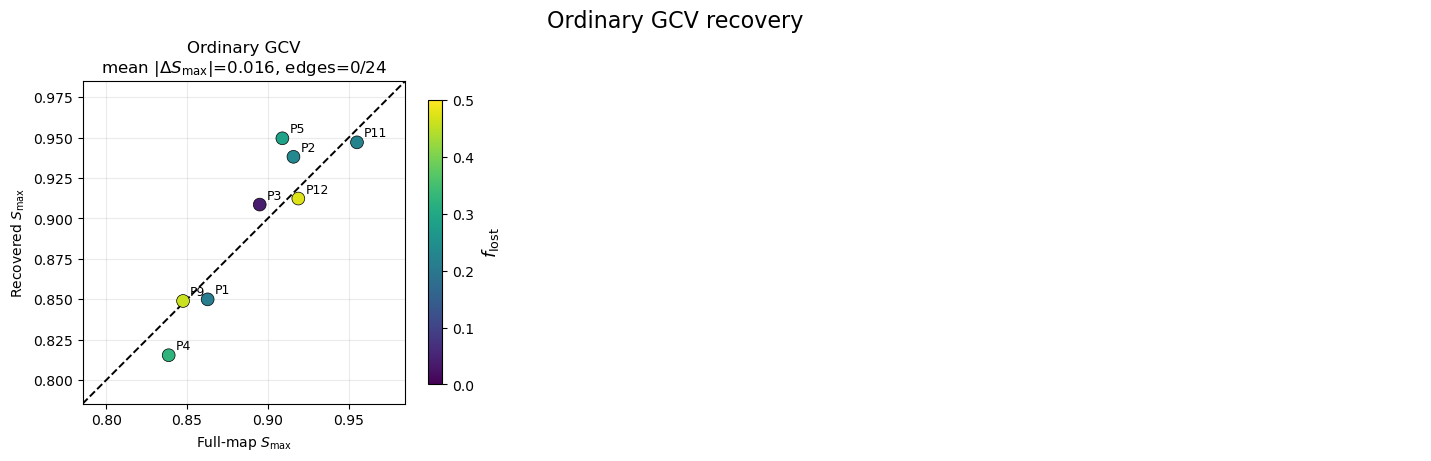

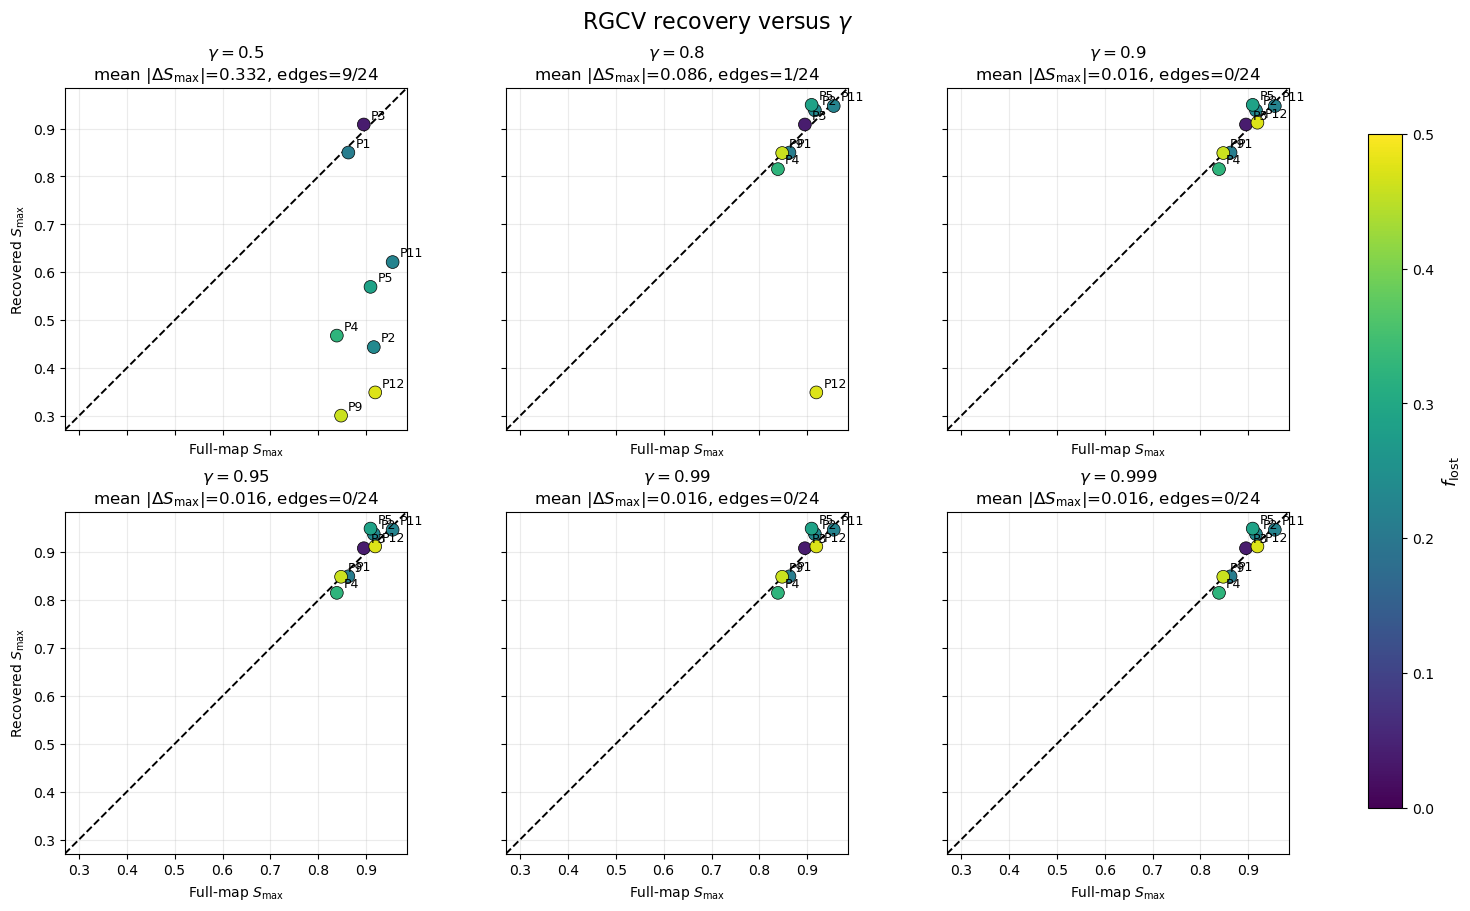

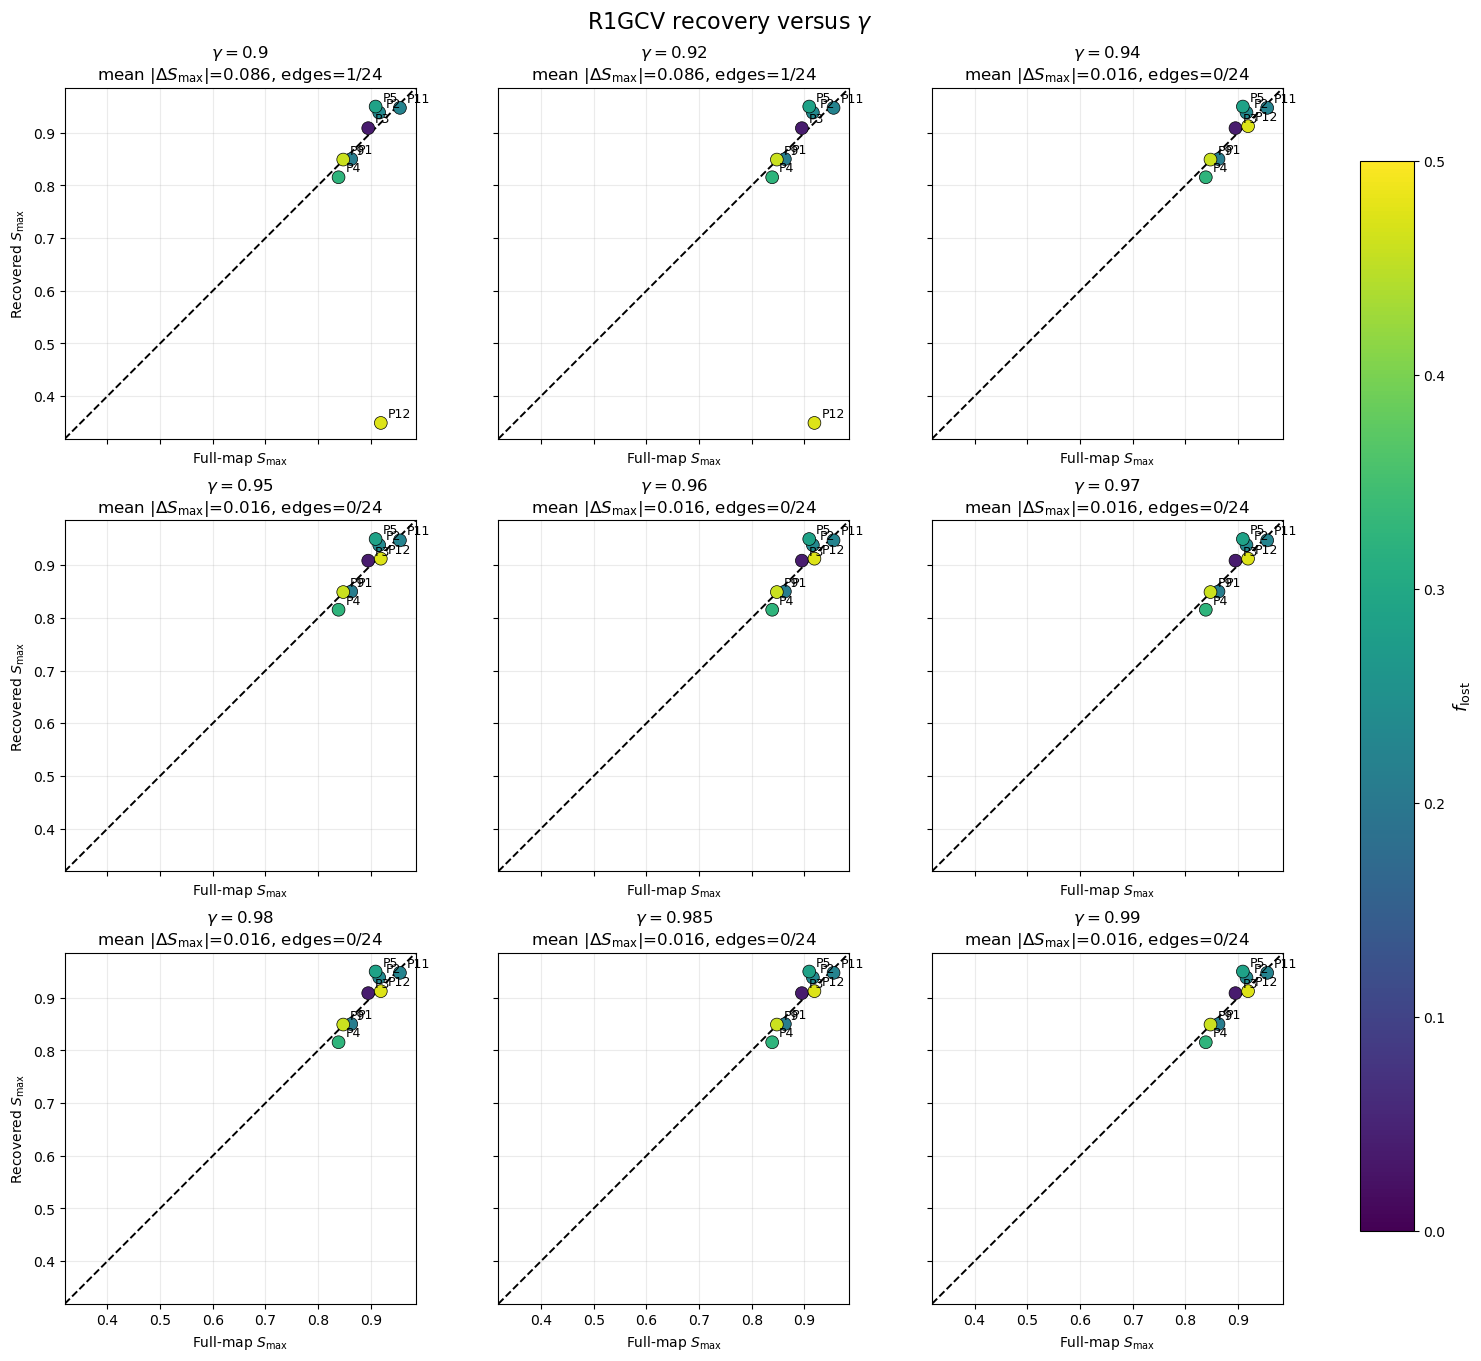

,Rank,Method,Gamma,mean_absolute_Smax_error,maximum_absolute_Smax_error,mean_S_curve_RMSE,exact_beta_fraction,mean_beta_error,boundary_selections
0,1,GCV,NaN,0.016075,0.040591,0.037326,1.0,0.0,0
1,1,RGCV,0.900,0.016075,0.040591,0.037326,1.0,0.0,0
2,2,RGCV,0.950,0.016075,0.040591,0.037326,1.0,0.0,0
3,3,RGCV,0.990,0.016075,0.040591,0.037326,1.0,0.0,0
4,4,RGCV,0.999,0.016075,0.040591,0.037326,1.0,0.0,0
5,1,R1GCV,0.940,0.016075,0.040591,0.037326,1.0,0.0,0
6,2,R1GCV,0.950,0.016075,0.040591,0.037326,1.0,0.0,0
7,3,R1GCV,0.960,0.016075,0.040591,0.037326,1.0,0.0,0
8,4,R1GCV,0.970,0.016075,0.040591,0.037326,1.0,0.0,0
9,5,R1GCV,0.980,0.016075,0.040591,0.037326,1.0,0.0,0



Best result for each method:


,Rank,Method,Gamma,mean_absolute_Smax_error,maximum_absolute_Smax_error,mean_S_curve_RMSE,exact_beta_fraction,mean_beta_error,boundary_selections
0,1,GCV,NaN,0.016075,0.040591,0.037326,1.0,0.0,0
1,1,RGCV,0.90,0.016075,0.040591,0.037326,1.0,0.0,0
2,1,R1GCV,0.94,0.016075,0.040591,0.037326,1.0,0.0,0


In [5]:
# ==================================================
# Test selected regularisation against injected truth
# ==================================================

def recover_S_with_fractions(
    data,
    fractions,
):
    """
    Recover the three mode products and calculate S(beta).
    """

    recovered_cross = apply_regularised_inverse(
        data["C_hat_ij"],
        data["mu_ij"],
        fractions["ij"],
    )

    recovered_power_i = apply_regularised_inverse(
        data["C_hat_ii"],
        data["mu_ii"],
        fractions["ii"],
    )

    recovered_power_j = apply_regularised_inverse(
        data["C_hat_jj"],
        data["mu_jj"],
        fractions["jj"],
    )

    recovered_S, valid = (
        calculate_S_curves_from_mode_products(
            recovered_cross,
            np.real(recovered_power_i),
            np.real(recovered_power_j),
            m_min=M_MIN,
        )
    )

    if not valid[0]:
        raise RuntimeError(
            "Recovered S(beta) is invalid."
        )

    return recovered_S[0]


geometry_by_pair = (
    geometry_table
    .set_index("Pair")
)

comparison_rows = []
recovery_curves = {}


for pair in sorted(pair_data):

    data = pair_data[pair]

    if data["f_lost"] > 0.5:
        continue

    geometry_row = geometry_by_pair.loc[pair]

    opening_angle = np.deg2rad(
        geometry_row.alpha_deg
    )

    centre_i = hp.ang2vec(
        np.deg2rad(
            geometry_row.theta_i_deg
        ),
        np.deg2rad(
            geometry_row.phi_i_deg
        ),
    )

    centre_j = hp.ang2vec(
        np.deg2rad(
            geometry_row.theta_j_deg
        ),
        np.deg2rad(
            geometry_row.phi_j_deg
        ),
    )

    # Full, unmasked circle samples.
    ring_i = sample_circle(
        full_map,
        centre_i,
        opening_angle,
    )

    ring_j = sample_circle(
        full_map,
        centre_j,
        opening_angle,
    )

    T_i = np.fft.fft(
        ring_i
    ) / NPHI

    T_j = np.fft.fft(
        ring_j
    ) / NPHI

    # True full-map mode products.
    C_full_ij = T_i * T_j
    C_full_ii = np.abs(T_i) ** 2
    C_full_jj = np.abs(T_j) ** 2

    full_S, full_valid = (
        calculate_S_curves_from_mode_products(
            C_full_ij,
            C_full_ii,
            C_full_jj,
            m_min=M_MIN,
        )
    )

    if not full_valid[0]:
        raise RuntimeError(
            f"Pair {pair}: full S(beta) is invalid."
        )

    full_S = full_S[0]

    full_beta = int(
        np.argmax(full_S)
    )

    full_Smax = float(
        full_S[full_beta]
    )

    method_fractions = {}

    for method in methods:
        method_fractions[method] = {
            quantity: regularisation_results[
                pair
            ][method][quantity]["f_reg"]
            for quantity in quantity_keys
        }

    recovery_curves[pair] = {
        "Full": full_S,
    }

    for method, fractions in (
        method_fractions.items()
    ):

        recovered_S = recover_S_with_fractions(
            data,
            fractions,
        )

        recovery_curves[
            pair
        ][method] = recovered_S

        recovered_beta = int(
            np.argmax(recovered_S)
        )

        recovered_Smax = float(
            recovered_S[recovered_beta]
        )

        beta_difference = abs(
            recovered_beta - full_beta
        )

        beta_error = min(
            beta_difference,
            NPHI - beta_difference,
        )

        comparison_rows.append(
            {
                "Pair": pair,
                "f_lost": data["f_lost"],
                "Method": method,
                "f_reg ij": fractions["ij"],
                "f_reg ii": fractions["ii"],
                "f_reg jj": fractions["jj"],
                "Full Smax": full_Smax,
                "Recovered Smax": (
                    recovered_Smax
                ),
                "Smax error": (
                    recovered_Smax
                    - full_Smax
                ),
                "Full beta bin": full_beta,
                "Recovered beta bin": (
                    recovered_beta
                ),
                "Beta error in bins": (
                    beta_error
                ),
                "S(beta) RMSE": float(
                    np.sqrt(
                        np.mean(
                            (
                                recovered_S
                                - full_S
                            ) ** 2
                        )
                    )
                ),
            }
        )


comparison_table = pd.DataFrame(
    comparison_rows
)

#display(comparison_table)

import matplotlib.pyplot as plt


# ==================================================
# Scan gamma and evaluate recovery
# ==================================================

RGCV_GAMMAS = [
    0.5,
    0.8,
    0.9,
    0.95,
    0.99,
    0.999,
]

R1GCV_GAMMAS = [
    0.90,
    0.92,
    0.94,
    0.95,
    0.96,
    0.97,
    0.98,
    0.985,
    0.99,
]

quantity_keys = {
    "ij": ("C_hat_ij", "mu_ij"),
    "ii": ("C_hat_ii", "mu_ii"),
    "jj": ("C_hat_jj", "mu_jj"),
}

# GCV has no gamma parameter.
gamma_sets = {
    "GCV": [None],
    "RGCV": RGCV_GAMMAS,
    "R1GCV": R1GCV_GAMMAS,
}


def select_gamma_fractions(
    data,
    method,
    gamma,
):
    """Select ij, ii and jj regularisation fractions."""

    fractions = {}
    boundary_count = 0

    for quantity, (
        C_hat_key,
        mu_key,
    ) in quantity_keys.items():

        if method == "GCV":
            curves = calculate_gcv_curves(
                C_hat=data[C_hat_key],
                mu=data[mu_key],
                f_reg_grid=F_REG_GRID,
            )

        elif method == "RGCV":
            curves = calculate_gcv_curves(
                C_hat=data[C_hat_key],
                mu=data[mu_key],
                f_reg_grid=F_REG_GRID,
                gamma_rgcv=gamma,
            )

        else:
            curves = calculate_gcv_curves(
                C_hat=data[C_hat_key],
                mu=data[mu_key],
                f_reg_grid=F_REG_GRID,
                gamma_r1gcv=gamma,
            )

        selected_index = int(
            np.argmin(curves[method])
        )

        fractions[quantity] = float(
            curves["f_reg"][selected_index]
        )

        if selected_index in (
            0,
            len(F_REG_GRID) - 1,
        ):
            boundary_count += 1

    return fractions, boundary_count


# ==================================================
# Recover S(beta) for every method and gamma
# ==================================================

gamma_recovery_rows = []

for method, gamma_values in gamma_sets.items():

    for gamma in gamma_values:

        for pair in sorted(pair_data):

            data = pair_data[pair]

            if data["f_lost"] > 0.5:
                continue

            fractions, boundary_count = (
                select_gamma_fractions(
                    data,
                    method,
                    gamma,
                )
            )

            recovered_S = recover_S_with_fractions(
                data,
                fractions,
            )

            full_S = recovery_curves[pair]["Full"]

            full_beta = int(
                np.argmax(full_S)
            )

            recovered_beta = int(
                np.argmax(recovered_S)
            )

            full_Smax = float(
                full_S[full_beta]
            )

            recovered_Smax = float(
                recovered_S[recovered_beta]
            )

            beta_difference = abs(
                recovered_beta - full_beta
            )

            beta_error = min(
                beta_difference,
                NPHI - beta_difference,
            )

            gamma_recovery_rows.append(
                {
                    "Method": method,
                    "Gamma": (
                        np.nan
                        if gamma is None
                        else gamma
                    ),
                    "Pair": pair,
                    "f_lost": data["f_lost"],
                    "f_reg ij": fractions["ij"],
                    "f_reg ii": fractions["ii"],
                    "f_reg jj": fractions["jj"],
                    "Boundary count": boundary_count,
                    "Full Smax": full_Smax,
                    "Recovered Smax": recovered_Smax,
                    "Smax error": (
                        recovered_Smax
                        - full_Smax
                    ),
                    "Beta error in bins": beta_error,
                    "S(beta) RMSE": float(
                        np.sqrt(
                            np.mean(
                                (
                                    recovered_S
                                    - full_S
                                ) ** 2
                            )
                        )
                    ),
                }
            )

gamma_recovery_table = pd.DataFrame(
    gamma_recovery_rows
)


# ==================================================
# Plot recovery for every method and gamma
# ==================================================

def plot_gamma_recovery(
    method,
    gamma_values,
):

    method_data = gamma_recovery_table.loc[
        gamma_recovery_table["Method"]
        == method
    ]

    minimum_value = min(
        method_data["Full Smax"].min(),
        method_data["Recovered Smax"].min(),
    ) - 0.03

    maximum_value = max(
        method_data["Full Smax"].max(),
        method_data["Recovered Smax"].max(),
    ) + 0.03

    number_of_columns = 3

    number_of_rows = int(
        np.ceil(
            len(gamma_values)
            / number_of_columns
        )
    )

    fig, axes = plt.subplots(
        number_of_rows,
        number_of_columns,
        figsize=(
            15,
            4.5 * number_of_rows,
        ),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    axes = np.atleast_1d(
        axes
    ).ravel()

    for axis, gamma in zip(
        axes,
        gamma_values,
    ):

        if method == "GCV":
            one_gamma = method_data
            panel_title = "Ordinary GCV"

        else:
            one_gamma = method_data.loc[
                np.isclose(
                    method_data["Gamma"],
                    gamma,
                )
            ]

            panel_title = (
                rf"$\gamma={gamma:g}$"
            )

        points = axis.scatter(
            one_gamma["Full Smax"],
            one_gamma["Recovered Smax"],
            c=one_gamma["f_lost"],
            cmap="viridis",
            vmin=0.0,
            vmax=0.5,
            s=85,
            edgecolor="black",
            linewidth=0.5,
            zorder=3,
        )

        for _, row in one_gamma.iterrows():

            axis.annotate(
                f"P{int(row['Pair'])}",
                (
                    row["Full Smax"],
                    row["Recovered Smax"],
                ),
                xytext=(5, 4),
                textcoords="offset points",
                fontsize=9,
            )

        axis.plot(
            [
                minimum_value,
                maximum_value,
            ],
            [
                minimum_value,
                maximum_value,
            ],
            "k--",
            linewidth=1.4,
        )

        mean_absolute_error = np.mean(
            np.abs(
                one_gamma["Smax error"]
            )
        )

        boundary_total = int(
            one_gamma[
                "Boundary count"
            ].sum()
        )

        boundary_possible = (
            3 * len(one_gamma)
        )

        axis.set_title(
            panel_title
            + "\n"
            + rf"mean $|\Delta S_{{\max}}|$"
            + f"={mean_absolute_error:.3f}, "
            + f"edges={boundary_total}/"
            + f"{boundary_possible}"
        )

        axis.set_xlabel(
            r"Full-map $S_{\max}$"
        )

        axis.set_xlim(
            minimum_value,
            maximum_value,
        )

        axis.set_ylim(
            minimum_value,
            maximum_value,
        )

        axis.set_aspect(
            "equal",
            adjustable="box",
        )

        axis.grid(
            alpha=0.25
        )

    for axis in axes[
        len(gamma_values):
    ]:
        axis.axis("off")

    for row_index in range(
        number_of_rows
    ):

        axes[
            row_index
            * number_of_columns
        ].set_ylabel(
            r"Recovered $S_{\max}$"
        )

    if method == "GCV":
        figure_title = (
            "Ordinary GCV recovery"
        )
    else:
        figure_title = (
            rf"{method} recovery versus $\gamma$"
        )

    fig.suptitle(
        figure_title,
        fontsize=16,
    )

    colour_bar = fig.colorbar(
        points,
        ax=axes[:len(gamma_values)],
        shrink=0.88,
    )

    colour_bar.set_label(
        r"$f_{\mathrm{lost}}$",
        fontsize=13,
    )

    plt.show()


plot_gamma_recovery(
    "GCV",
    [None],
)

plot_gamma_recovery(
    "RGCV",
    RGCV_GAMMAS,
)

plot_gamma_recovery(
    "R1GCV",
    R1GCV_GAMMAS,
)


# ==================================================
# Summary statistics and ranking
# ==================================================

gamma_statistics = (
    gamma_recovery_table
    .groupby(
        [
            "Method",
            "Gamma",
        ],
        as_index=False,
        dropna=False,
    )
    .agg(
        mean_absolute_Smax_error=(
            "Smax error",
            lambda x: np.mean(
                np.abs(x)
            ),
        ),
        maximum_absolute_Smax_error=(
            "Smax error",
            lambda x: np.max(
                np.abs(x)
            ),
        ),
        mean_S_curve_RMSE=(
            "S(beta) RMSE",
            "mean",
        ),
        exact_beta_fraction=(
            "Beta error in bins",
            lambda x: np.mean(
                x == 0
            ),
        ),
        mean_beta_error=(
            "Beta error in bins",
            "mean",
        ),
        boundary_selections=(
            "Boundary count",
            "sum",
        ),
    )
)


# ==================================================
# Rank within each method
# ==================================================

ranking_rows = []

for method in gamma_sets:

    method_statistics = (
        gamma_statistics.loc[
            gamma_statistics["Method"]
            == method
        ]
        .copy()
    )

    # Prefer solutions without boundary minima.
    interior = method_statistics.loc[
        method_statistics[
            "boundary_selections"
        ] == 0
    ]

    if len(interior) > 0:
        method_statistics = interior

    method_statistics = (
        method_statistics
        .sort_values(
            [
                "exact_beta_fraction",
                "mean_absolute_Smax_error",
                "mean_S_curve_RMSE",
            ],
            ascending=[
                False,
                True,
                True,
            ],
        )
        .reset_index(drop=True)
    )

    method_statistics.insert(
        0,
        "Rank",
        np.arange(
            1,
            len(method_statistics) + 1,
        ),
    )

    ranking_rows.append(
        method_statistics
    )


gamma_ranking = pd.concat(
    ranking_rows,
    ignore_index=True,
)

display(gamma_ranking)


# ==================================================
# Best result from each method
# ==================================================

best_gamma = (
    gamma_ranking.loc[
        gamma_ranking["Rank"] == 1
    ]
    .reset_index(drop=True)
)

print(
    "\nBest result for each method:"
)

display(best_gamma)

## Calibrate RGCV on Null Realisations

RGCV is applied to 1000 independent null CMB realisations to calibrate the robustness parameter $\gamma$ without using an injected-topology signal.

For each trial $\gamma$, the reconstruction bias is measured by

$$
\Delta S_{\max}
\equiv
S_{\max}^{\rm rec}
-
S_{\max}^{\rm full}.
$$

The candidate value is chosen from the null ensemble by requiring no boundary selections and minimising

$$
\left|
\left\langle
\Delta S_{\max}
\right\rangle_{\rm null}
\right|.
$$

The selected RGCV recovery is then compared with the E1 recovery in the
$S_{\max}^{\rm full}$--$S_{\max}^{\rm rec}$ plane to check whether the same regularisation procedure behaves consistently for both null and signal cases.

(The choice of initial f_reg range here need further investigation)

/tmp/ipykernel_3811769/2139533400.py:104: RuntimeWarning: divide by zero encountered in divide
  residual_power


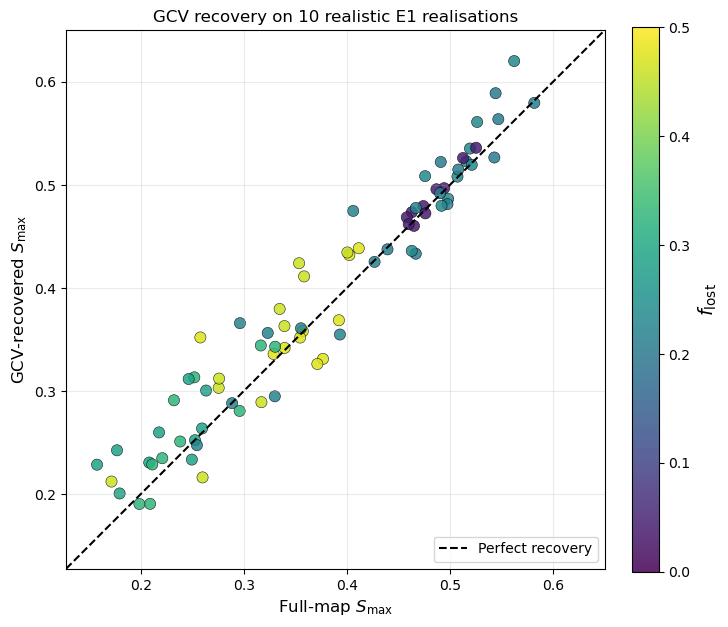

/tmp/ipykernel_3811769/2349368841.py:657: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  full_null_map = hp.synfast(


Completed 1/1000
Completed 50/1000
Completed 100/1000
Completed 150/1000
Completed 200/1000
Completed 250/1000
Completed 300/1000
Completed 350/1000
Completed 400/1000
Completed 450/1000
Completed 500/1000
Completed 550/1000
Completed 600/1000
Completed 650/1000
Completed 700/1000
Completed 750/1000
Completed 800/1000
Completed 850/1000
Completed 900/1000
Completed 950/1000
Completed 1000/1000


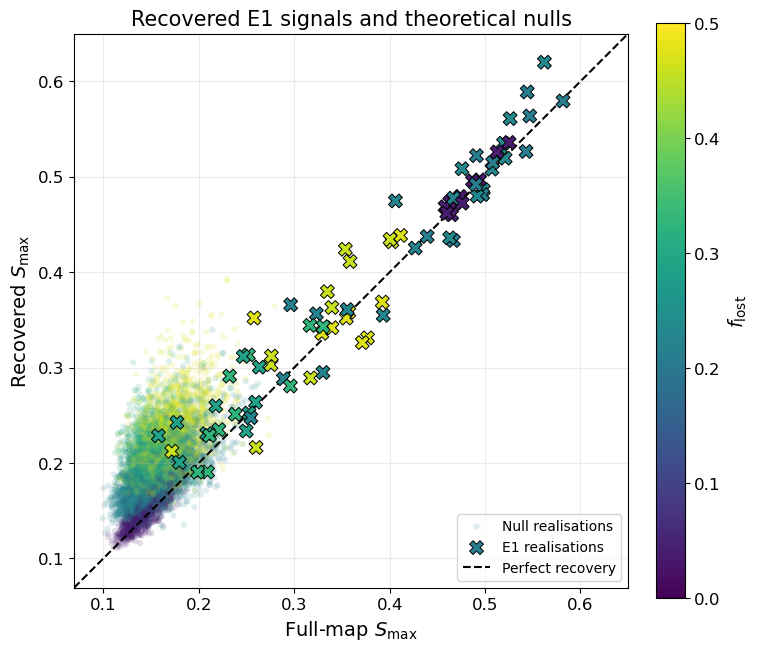


E1 recovery statistics
Recoveries:             80
Mean |Smax error|:      0.024811
Maximum |Smax error|:   0.094113
Mean S(beta) RMSE:      0.036808
Exact-beta fraction:    0.950

Null recovery statistics
RGCV gamma:             0.800
Recoveries:             8000
Mean |Smax error|:      0.041497
Maximum |Smax error|:   0.206311
Mean S(beta) RMSE:      0.037137
Exact-beta fraction:    0.285


In [8]:
from pathlib import Path

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==================================================
# Input E1 maps
# ==================================================

src_dir = root / "src"

e1_map_files = sorted(
    src_dir.glob(
        "E1_fgres_r???.fits"
    )
)

if len(e1_map_files) != 10:
    raise RuntimeError(
        f"Expected 10 E1 maps, "
        f"found {len(e1_map_files)}."
    )


geometry_by_pair = (
    geometry_table
    .set_index("Pair")
)

quantity_keys = {
    "ij": ("C_hat_ij", "mu_ij"),
    "ii": ("C_hat_ii", "mu_ii"),
    "jj": ("C_hat_jj", "mu_jj"),
}


# ==================================================
# Apply GCV to all 10 E1 realisations
# ==================================================

recovery_rows = []

for map_file in e1_map_files:

    realisation = (
        map_file.stem.split("_r")[-1]
    )

    full_map_realistic = hp.read_map(
        map_file,
        field=0,
        dtype=np.float64,
    )

    for pair in sorted(pair_data):

        data = pair_data[pair]

        if data["f_lost"] > 0.5:
            continue

        geometry_row = (
            geometry_by_pair.loc[pair]
        )

        opening_angle = np.deg2rad(
            geometry_row.alpha_deg
        )

        centre_i = hp.ang2vec(
            np.deg2rad(
                geometry_row.theta_i_deg
            ),
            np.deg2rad(
                geometry_row.phi_i_deg
            ),
        )

        centre_j = hp.ang2vec(
            np.deg2rad(
                geometry_row.theta_j_deg
            ),
            np.deg2rad(
                geometry_row.phi_j_deg
            ),
        )

        # Full circle samples.
        ring_i = sample_circle(
            full_map_realistic,
            centre_i,
            opening_angle,
        )

        ring_j = sample_circle(
            full_map_realistic,
            centre_j,
            opening_angle,
        )

        # Same Galactic mask used for coupling matrices.
        w_i = (
            sample_circle(
                binary_mask,
                centre_i,
                opening_angle,
            )
            >= MASK_THRESHOLD
        ).astype(float)

        w_j = (
            sample_circle(
                binary_mask,
                centre_j,
                opening_angle,
            )
            >= MASK_THRESHOLD
        ).astype(float)

        # Full Fourier coefficients.
        T_i = np.fft.fft(
            ring_i
        ) / NPHI

        T_j = np.fft.fft(
            ring_j
        ) / NPHI

        # Masked Fourier coefficients.
        T_hat_i = np.fft.fft(
            w_i * ring_i
        ) / NPHI

        T_hat_j = np.fft.fft(
            w_j * ring_j
        ) / NPHI

        # Full-map mode products.
        C_full_ij = T_i * T_j
        C_full_ii = np.abs(T_i) ** 2
        C_full_jj = np.abs(T_j) ** 2

        # Masked data supplied to GCV.
        current_data = {
            "C_hat_ij": (
                T_hat_i * T_hat_j
            ),
            "C_hat_ii": (
                np.abs(T_hat_i) ** 2
            ),
            "C_hat_jj": (
                np.abs(T_hat_j) ** 2
            ),
            "mu_ij": data["mu_ij"],
            "mu_ii": data["mu_ii"],
            "mu_jj": data["mu_jj"],
        }

        # Select GCV f_reg separately
        # for ij, ii and jj.
        fractions = {}

        for quantity, (
            C_hat_key,
            mu_key,
        ) in quantity_keys.items():

            curves = calculate_gcv_curves(
                C_hat=current_data[
                    C_hat_key
                ],
                mu=current_data[
                    mu_key
                ],
                f_reg_grid=F_REG_GRID,
            )

            selected_index = int(
                np.argmin(
                    curves["GCV"]
                )
            )

            fractions[quantity] = float(
                curves["f_reg"][
                    selected_index
                ]
            )

        # Full S(beta).
        full_S, full_valid = (
            calculate_S_curves_from_mode_products(
                C_full_ij,
                C_full_ii,
                C_full_jj,
                m_min=M_MIN,
            )
        )

        if not full_valid[0]:
            raise RuntimeError(
                f"r{realisation}, pair {pair}: "
                "invalid full S(beta)."
            )

        full_S = full_S[0]

        # GCV recovery.
        recovered_S = (
            recover_S_with_fractions(
                current_data,
                fractions,
            )
        )

        full_beta = int(
            np.argmax(full_S)
        )

        recovered_beta = int(
            np.argmax(recovered_S)
        )

        full_Smax = float(
            full_S[full_beta]
        )

        recovered_Smax = float(
            recovered_S[
                recovered_beta
            ]
        )

        beta_difference = abs(
            recovered_beta
            - full_beta
        )

        beta_error = min(
            beta_difference,
            NPHI - beta_difference,
        )

        recovery_rows.append(
            {
                "Realisation": (
                    f"r{realisation}"
                ),
                "Pair": pair,
                "f_lost": data["f_lost"],
                "f_reg ij": fractions["ij"],
                "f_reg ii": fractions["ii"],
                "f_reg jj": fractions["jj"],
                "Full Smax": full_Smax,
                "Recovered Smax": (
                    recovered_Smax
                ),
                "Smax error": (
                    recovered_Smax
                    - full_Smax
                ),
                "Full beta bin": (
                    full_beta
                ),
                "Recovered beta bin": (
                    recovered_beta
                ),
                "Beta error in bins": (
                    beta_error
                ),
                "S(beta) RMSE": float(
                    np.sqrt(
                        np.mean(
                            (
                                recovered_S
                                - full_S
                            ) ** 2
                        )
                    )
                ),
            }
        )


gcv_e1_recovery_table = pd.DataFrame(
    recovery_rows
)


# ==================================================
# E1 summary statistics
# ==================================================

mean_absolute_error = float(
    np.mean(
        np.abs(
            gcv_e1_recovery_table[
                "Smax error"
            ]
        )
    )
)

maximum_absolute_error = float(
    np.max(
        np.abs(
            gcv_e1_recovery_table[
                "Smax error"
            ]
        )
    )
)

mean_curve_rmse = float(
    gcv_e1_recovery_table[
        "S(beta) RMSE"
    ].mean()
)

exact_beta_fraction = float(
    np.mean(
        gcv_e1_recovery_table[
            "Beta error in bins"
        ] == 0
    )
)


# ==================================================
# E1 recovery plot
# ==================================================

minimum_value = min(
    gcv_e1_recovery_table[
        "Full Smax"
    ].min(),
    gcv_e1_recovery_table[
        "Recovered Smax"
    ].min(),
) - 0.03

maximum_value = max(
    gcv_e1_recovery_table[
        "Full Smax"
    ].max(),
    gcv_e1_recovery_table[
        "Recovered Smax"
    ].max(),
) + 0.03


fig, axis = plt.subplots(
    figsize=(7.2, 6.2),
    constrained_layout=True,
)

points = axis.scatter(
    gcv_e1_recovery_table[
        "Full Smax"
    ],
    gcv_e1_recovery_table[
        "Recovered Smax"
    ],
    c=gcv_e1_recovery_table[
        "f_lost"
    ],
    cmap="viridis",
    vmin=0.0,
    vmax=0.5,
    s=65,
    edgecolor="black",
    linewidth=0.4,
    alpha=0.85,
)

axis.plot(
    [
        minimum_value,
        maximum_value,
    ],
    [
        minimum_value,
        maximum_value,
    ],
    "k--",
    linewidth=1.5,
    label="Perfect recovery",
)

axis.set_xlim(
    minimum_value,
    maximum_value,
)

axis.set_ylim(
    minimum_value,
    maximum_value,
)

axis.set_aspect(
    "equal",
    adjustable="box",
)

axis.set_xlabel(
    r"Full-map $S_{\max}$",
    fontsize=12,
)

axis.set_ylabel(
    r"GCV-recovered $S_{\max}$",
    fontsize=12,
)

axis.set_title(
    "GCV recovery on 10 realistic E1 realisations"
)

axis.grid(
    alpha=0.25
)

axis.legend(
    loc="lower right"
)

colour_bar = fig.colorbar(
    points,
    ax=axis,
)

colour_bar.set_label(
    r"$f_{\mathrm{lost}}$",
    fontsize=14,
)

plt.show()


# ==================================================
# Null settings
# ==================================================

NUMBER_OF_NULLS = 1000
NULL_SEED_BASE = 50000
NSIDE_NULL = 128
LMAX_NULL = 300

RGCV_GAMMA_GRID = np.round(
    np.arange(
        0.800,
        0.861,
        0.001,
    ),
    3,
)

power_spectrum_file = (
    root
    / "src"
    / "COM_PowerSpect_CMB-TT-full_R3.01.txt"
)


# ==================================================
# Read D_ell and convert to C_ell
# ==================================================

spectrum = np.loadtxt(
    power_spectrum_file,
    comments="#",
)

cl = np.zeros(
    LMAX_NULL + 1,
    dtype=float,
)

for ell, dl in spectrum[:, :2]:

    ell = int(ell)

    if 2 <= ell <= LMAX_NULL:

        cl[ell] = (
            dl
            * 1.0e-12
            * 2.0
            * np.pi
            / (
                ell
                * (ell + 1.0)
            )
        )

cl[:2] = 0.0


# ==================================================
# Precalculate geometry and masks
# ==================================================

pair_setup = {}

for pair in sorted(pair_data):

    data = pair_data[pair]

    if data["f_lost"] > 0.5:
        continue

    geometry_row = (
        geometry_by_pair.loc[pair]
    )

    opening_angle = np.deg2rad(
        geometry_row.alpha_deg
    )

    centre_i = hp.ang2vec(
        np.deg2rad(
            geometry_row.theta_i_deg
        ),
        np.deg2rad(
            geometry_row.phi_i_deg
        ),
    )

    centre_j = hp.ang2vec(
        np.deg2rad(
            geometry_row.theta_j_deg
        ),
        np.deg2rad(
            geometry_row.phi_j_deg
        ),
    )

    w_i = (
        sample_circle(
            binary_mask,
            centre_i,
            opening_angle,
        )
        >= MASK_THRESHOLD
    ).astype(float)

    w_j = (
        sample_circle(
            binary_mask,
            centre_j,
            opening_angle,
        )
        >= MASK_THRESHOLD
    ).astype(float)

    pair_setup[pair] = {
        "opening_angle": opening_angle,
        "centre_i": centre_i,
        "centre_j": centre_j,
        "w_i": w_i,
        "w_j": w_j,
    }


# ==================================================
# Select RGCV regularisation for every gamma
# ==================================================

def select_rgcv_fractions(
    current_data,
    gamma_grid,
):
    """
    Select ij, ii and jj f_reg for every RGCV gamma.
    """

    selections = {
        float(gamma): {
            "fractions": {},
            "boundary_count": 0,
        }
        for gamma in gamma_grid
    }

    for quantity, (
        C_hat_key,
        mu_key,
    ) in quantity_keys.items():

        curves = calculate_gcv_curves(
            C_hat=current_data[
                C_hat_key
            ],
            mu=current_data[
                mu_key
            ],
            f_reg_grid=F_REG_GRID,
        )

        for gamma in gamma_grid:

            gamma = float(gamma)

            V_RGCV = (
                gamma
                + (
                    1.0 - gamma
                )
                * curves["d2"]
            ) * curves["GCV"]

            selected_index = int(
                np.nanargmin(
                    V_RGCV
                )
            )

            selections[
                gamma
            ]["fractions"][quantity] = float(
                curves["f_reg"][
                    selected_index
                ]
            )

            if selected_index in (
                0,
                len(F_REG_GRID) - 1,
            ):
                selections[
                    gamma
                ][
                    "boundary_count"
                ] += 1

    return selections


# ==================================================
# Apply RGCV to 1000 null maps
# ==================================================

null_recovery_rows = []

for realisation in range(
    NUMBER_OF_NULLS
):

    np.random.seed(
        NULL_SEED_BASE
        + realisation
    )

    full_null_map = hp.synfast(
        cl,
        nside=NSIDE_NULL,
        lmax=LMAX_NULL,
        pixwin=False,
        new=True,
        verbose=False,
    )

    for pair in sorted(
        pair_setup
    ):

        data = pair_data[pair]
        setup = pair_setup[pair]

        # Full circle samples.
        ring_i = sample_circle(
            full_null_map,
            setup["centre_i"],
            setup["opening_angle"],
        )

        ring_j = sample_circle(
            full_null_map,
            setup["centre_j"],
            setup["opening_angle"],
        )

        # Full Fourier coefficients.
        T_i = np.fft.fft(
            ring_i
        ) / NPHI

        T_j = np.fft.fft(
            ring_j
        ) / NPHI

        # Masked Fourier coefficients.
        T_hat_i = np.fft.fft(
            setup["w_i"]
            * ring_i
        ) / NPHI

        T_hat_j = np.fft.fft(
            setup["w_j"]
            * ring_j
        ) / NPHI

        # Full-map mode products.
        C_full_ij = (
            T_i * T_j
        )

        C_full_ii = (
            np.abs(T_i) ** 2
        )

        C_full_jj = (
            np.abs(T_j) ** 2
        )

        # Masked null data supplied to RGCV.
        current_data = {
            "C_hat_ij": (
                T_hat_i
                * T_hat_j
            ),
            "C_hat_ii": (
                np.abs(
                    T_hat_i
                ) ** 2
            ),
            "C_hat_jj": (
                np.abs(
                    T_hat_j
                ) ** 2
            ),
            "mu_ij": data["mu_ij"],
            "mu_ii": data["mu_ii"],
            "mu_jj": data["mu_jj"],
        }

        # Full-map S(beta).
        full_S, valid = (
            calculate_S_curves_from_mode_products(
                C_full_ij,
                C_full_ii,
                C_full_jj,
                m_min=M_MIN,
            )
        )

        if not valid[0]:

            raise RuntimeError(
                f"Null {realisation}, "
                f"pair {pair}: "
                "invalid full S(beta)."
            )

        full_S = full_S[0]

        full_beta = int(
            np.argmax(
                full_S
            )
        )

        full_Smax = float(
            full_S[
                full_beta
            ]
        )

        # Select f_reg for every gamma.
        selections = (
            select_rgcv_fractions(
                current_data,
                RGCV_GAMMA_GRID,
            )
        )

        for gamma in (
            RGCV_GAMMA_GRID
        ):

            gamma = float(
                gamma
            )

            fractions = selections[
                gamma
            ]["fractions"]

            boundary_count = selections[
                gamma
            ]["boundary_count"]

            recovered_S = (
                recover_S_with_fractions(
                    current_data,
                    fractions,
                )
            )

            recovered_beta = int(
                np.argmax(
                    recovered_S
                )
            )

            recovered_Smax = float(
                recovered_S[
                    recovered_beta
                ]
            )

            beta_difference = abs(
                recovered_beta
                - full_beta
            )

            beta_error = min(
                beta_difference,
                NPHI
                - beta_difference,
            )

            null_recovery_rows.append(
                {
                    "Realisation": (
                        realisation
                    ),
                    "Pair": pair,
                    "Gamma": gamma,
                    "f_lost": (
                        data["f_lost"]
                    ),
                    "f_reg ij": (
                        fractions["ij"]
                    ),
                    "f_reg ii": (
                        fractions["ii"]
                    ),
                    "f_reg jj": (
                        fractions["jj"]
                    ),
                    "Boundary count": (
                        boundary_count
                    ),
                    "Full Smax": (
                        full_Smax
                    ),
                    "Recovered Smax": (
                        recovered_Smax
                    ),
                    "Smax error": (
                        recovered_Smax
                        - full_Smax
                    ),
                    "Beta error in bins": (
                        beta_error
                    ),
                    "S(beta) RMSE": float(
                        np.sqrt(
                            np.mean(
                                (
                                    recovered_S
                                    - full_S
                                ) ** 2
                            )
                        )
                    ),
                }
            )

    if (
        (realisation + 1) % 50 == 0
        or realisation == 0
    ):

        print(
            f"Completed "
            f"{realisation + 1}/"
            f"{NUMBER_OF_NULLS}"
        )


rgcv_null_recovery_table = (
    pd.DataFrame(
        null_recovery_rows
    )
)


# ==================================================
# Null bias for each gamma
# ==================================================

# First average over pairs within each null map.
per_map_bias = (
    rgcv_null_recovery_table
    .groupby(
        [
            "Gamma",
            "Realisation",
        ],
        as_index=False,
    )
    .agg(
        mean_Smax_error=(
            "Smax error",
            "mean",
        ),
    )
)


# Then average over independent null maps.
gamma_statistics = (
    per_map_bias
    .groupby(
        "Gamma",
        as_index=False,
    )
    .agg(
        mean_signed_bias=(
            "mean_Smax_error",
            "mean",
        ),
        bias_standard_deviation=(
            "mean_Smax_error",
            "std",
        ),
        number_of_maps=(
            "Realisation",
            "count",
        ),
    )
)

gamma_statistics[
    "bias_standard_error"
] = (
    gamma_statistics[
        "bias_standard_deviation"
    ]
    / np.sqrt(
        gamma_statistics[
            "number_of_maps"
        ]
    )
)

gamma_statistics[
    "two_sigma_error"
] = (
    2.0
    * gamma_statistics[
        "bias_standard_error"
    ]
)


# ==================================================
# Boundary diagnostic for gamma selection
# ==================================================

boundary_statistics = (
    rgcv_null_recovery_table
    .groupby(
        "Gamma",
        as_index=False,
    )
    .agg(
        boundary_selections=(
            "Boundary count",
            "sum",
        ),
    )
)

gamma_statistics = (
    gamma_statistics
    .merge(
        boundary_statistics,
        on="Gamma",
        how="left",
    )
)


# ==================================================
# Select candidate gamma
# ==================================================

acceptable = (
    gamma_statistics.loc[
        gamma_statistics[
            "boundary_selections"
        ] == 0
    ]
    .copy()
)

if len(acceptable) > 0:

    best_index = (
        acceptable[
            "mean_signed_bias"
        ]
        .abs()
        .idxmin()
    )

    RGCV_CANDIDATE_GAMMA = float(
        acceptable.loc[
            best_index,
            "Gamma",
        ]
    )

else:

    minimum_boundaries = int(
        gamma_statistics[
            "boundary_selections"
        ].min()
    )

    acceptable = (
        gamma_statistics.loc[
            gamma_statistics[
                "boundary_selections"
            ] == minimum_boundaries
        ]
        .copy()
    )

    best_index = (
        acceptable[
            "mean_signed_bias"
        ]
        .abs()
        .idxmin()
    )

    RGCV_CANDIDATE_GAMMA = float(
        acceptable.loc[
            best_index,
            "Gamma",
        ]
    )


# ==================================================
# Null results at candidate gamma
# ==================================================

selected_rows = (
    rgcv_null_recovery_table.loc[
        np.isclose(
            rgcv_null_recovery_table[
                "Gamma"
            ],
            RGCV_CANDIDATE_GAMMA,
        )
    ]
    .copy()
)

selected_statistics = (
    gamma_statistics.loc[
        np.isclose(
            gamma_statistics[
                "Gamma"
            ],
            RGCV_CANDIDATE_GAMMA,
        )
    ]
    .iloc[0]
)

upward_fraction = float(
    np.mean(
        selected_rows[
            "Smax error"
        ] > 0.0
    )
)

null_mean_curve_rmse = float(
    selected_rows[
        "S(beta) RMSE"
    ].mean()
)

null_exact_beta_fraction = float(
    np.mean(
        selected_rows[
            "Beta error in bins"
        ] == 0
    )
)

# ==================================================
# E1 and null recovery statistics
# ==================================================

e1_table = gcv_e1_recovery_table
null_table = selected_rows


# --------------------------------------------------
# E1 statistics
# --------------------------------------------------

e1_mean_absolute_error = float(
    np.mean(
        np.abs(
            e1_table["Smax error"]
        )
    )
)

e1_maximum_absolute_error = float(
    np.max(
        np.abs(
            e1_table["Smax error"]
        )
    )
)

e1_mean_curve_rmse = float(
    e1_table[
        "S(beta) RMSE"
    ].mean()
)

e1_exact_beta_fraction = float(
    np.mean(
        e1_table[
            "Beta error in bins"
        ] == 0
    )
)


# --------------------------------------------------
# Null statistics at selected RGCV gamma
# --------------------------------------------------

null_mean_absolute_error = float(
    np.mean(
        np.abs(
            null_table["Smax error"]
        )
    )
)

null_maximum_absolute_error = float(
    np.max(
        np.abs(
            null_table["Smax error"]
        )
    )
)

null_mean_curve_rmse = float(
    null_table[
        "S(beta) RMSE"
    ].mean()
)

null_exact_beta_fraction = float(
    np.mean(
        null_table[
            "Beta error in bins"
        ] == 0
    )
)


# ==================================================
# Plot E1 signals and nulls together
# ==================================================

minimum_value = min(
    null_table[
        "Full Smax"
    ].min(),
    null_table[
        "Recovered Smax"
    ].min(),
    e1_table[
        "Full Smax"
    ].min(),
    e1_table[
        "Recovered Smax"
    ].min(),
) - 0.03

maximum_value = max(
    null_table[
        "Full Smax"
    ].max(),
    null_table[
        "Recovered Smax"
    ].max(),
    e1_table[
        "Full Smax"
    ].max(),
    e1_table[
        "Recovered Smax"
    ].max(),
) + 0.03


fig, axis = plt.subplots(
    figsize=(7.5, 6.5),
    constrained_layout=True,
)


# Null realisations.
axis.scatter(
    null_table[
        "Full Smax"
    ],
    null_table[
        "Recovered Smax"
    ],
    c=null_table[
        "f_lost"
    ],
    cmap="viridis",
    vmin=0.0,
    vmax=0.5,
    marker="o",
    s=20,
    alpha=0.15,
    linewidth=0.0,
    label="Null realisations",
)


# E1 signal realisations.
e1_points = axis.scatter(
    e1_table[
        "Full Smax"
    ],
    e1_table[
        "Recovered Smax"
    ],
    c=e1_table[
        "f_lost"
    ],
    cmap="viridis",
    vmin=0.0,
    vmax=0.5,
    marker="X",
    s=100,
    edgecolor="black",
    linewidth=0.7,
    label="E1 realisations",
    zorder=3,
)


# Perfect-recovery line.
axis.plot(
    [
        minimum_value,
        maximum_value,
    ],
    [
        minimum_value,
        maximum_value,
    ],
    "k--",
    linewidth=1.5,
    label="Perfect recovery",
)

axis.set_xlim(
    minimum_value,
    maximum_value,
)

axis.set_ylim(
    minimum_value,
    maximum_value,
)

axis.set_aspect(
    "equal",
    adjustable="box",
)

axis.set_xlabel(
    r"Full-map $S_{\max}$",
    fontsize=14,
)

axis.set_ylabel(
    r"Recovered $S_{\max}$",
    fontsize=14,
)

axis.set_title(
    "Recovered E1 signals and theoretical nulls",
    fontsize=15,
)

axis.tick_params(
    labelsize=12,
)

axis.grid(
    alpha=0.25,
)

axis.legend(
    loc="lower right",
    fontsize=10,
)

colour_bar = fig.colorbar(
    e1_points,
    ax=axis,
)

colour_bar.set_label(
    r"$f_{\mathrm{lost}}$",
    fontsize=14,
)

colour_bar.ax.tick_params(
    labelsize=12,
)

plt.show()


# ==================================================
# Print E1 recovery statistics
# ==================================================

print(
    "\nE1 recovery statistics"
)

print(
    f"Recoveries:             "
    f"{len(e1_table)}"
)

print(
    f"Mean |Smax error|:      "
    f"{e1_mean_absolute_error:.6f}"
)

print(
    f"Maximum |Smax error|:   "
    f"{e1_maximum_absolute_error:.6f}"
)

print(
    f"Mean S(beta) RMSE:      "
    f"{e1_mean_curve_rmse:.6f}"
)

print(
    f"Exact-beta fraction:    "
    f"{e1_exact_beta_fraction:.3f}"
)


# ==================================================
# Print null recovery statistics
# ==================================================

print(
    "\nNull recovery statistics"
)

print(
    f"RGCV gamma:             "
    f"{RGCV_CANDIDATE_GAMMA:.3f}"
)

print(
    f"Recoveries:             "
    f"{len(null_table)}"
)

print(
    f"Mean |Smax error|:      "
    f"{null_mean_absolute_error:.6f}"
)

print(
    f"Maximum |Smax error|:   "
    f"{null_maximum_absolute_error:.6f}"
)

print(
    f"Mean S(beta) RMSE:      "
    f"{null_mean_curve_rmse:.6f}"
)

print(
    f"Exact-beta fraction:    "
    f"{null_exact_beta_fraction:.3f}"
)

,Pair,f_lost,detected_95p4,detected_99p7
0,1,0.208984,10,10
1,2,0.234375,10,10
2,3,0.037109,10,10
3,4,0.324219,5,3
4,5,0.287109,4,1
5,9,0.458984,8,6
6,11,0.222656,9,7
7,12,0.472656,10,3


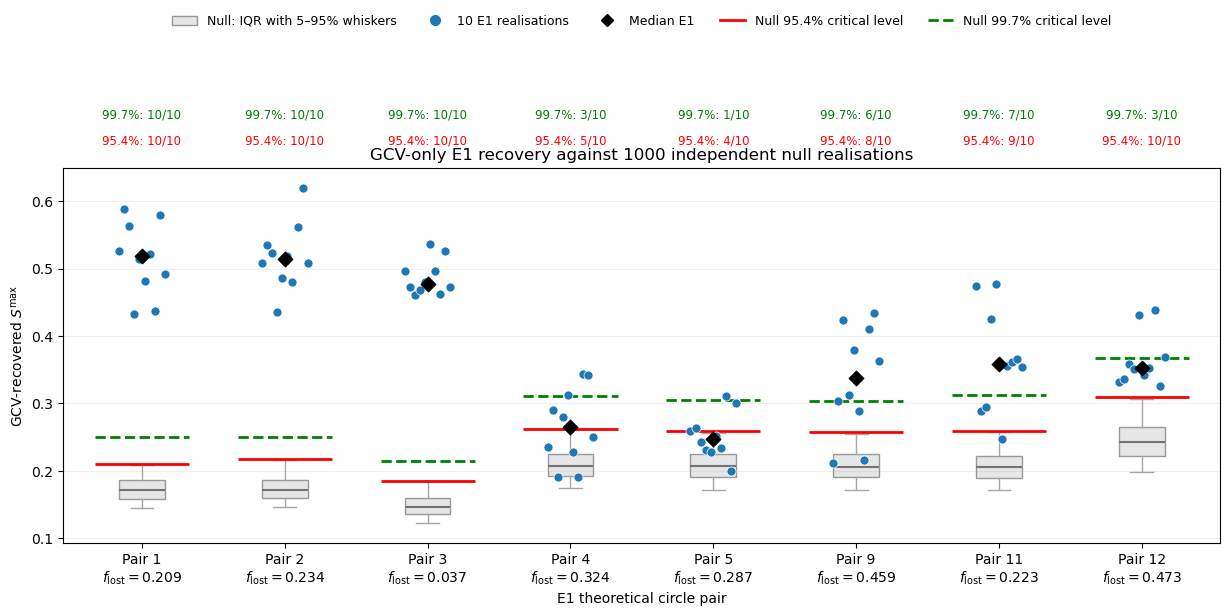

Saved: /hydrarepo/xluo/circles-in-the-sky/GCV_only_E1_recovery_against_1000_null_boxplot.pdf
Pairs recoverable:      8/13
Above 95.4% null:       66/80 (82.5%)
Above 99.7% null:       50/80 (62.5%)


In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ==================================================
# GCV-only results
# ==================================================

null_table = selected_rows.copy()
e1_table = gcv_e1_recovery_table.copy()

e1_column = "Recovered Smax"
null_column = "Recovered Smax"


# ==================================================
# Common usable pairs
# ==================================================

pair_ids = sorted(
    set(
        e1_table["Pair"]
    ).intersection(
        null_table["Pair"]
    )
)

if len(pair_ids) != 8:
    raise RuntimeError(
        f"Expected 8 usable pairs, "
        f"found {pair_ids}."
    )


# ==================================================
# Checks
# ==================================================

for pair in pair_ids:

    number_e1 = np.sum(
        e1_table["Pair"] == pair
    )

    number_null = np.sum(
        null_table["Pair"] == pair
    )

    if number_e1 != 10:
        raise RuntimeError(
            f"Pair {pair}: expected "
            f"10 E1 values, "
            f"found {number_e1}."
        )

    if number_null != 1000:
        raise RuntimeError(
            f"Pair {pair}: expected "
            f"1000 null values, "
            f"found {number_null}."
        )


# ==================================================
# Figure
# ==================================================

fig, axis = plt.subplots(
    figsize=(13, 6.7),
)

# Leave separate space for detection labels and legend.
fig.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.17,
    top=0.73,
)

positions = np.arange(
    len(pair_ids)
)


# ==================================================
# Compact null box plots
#
# Box: 25th–75th percentiles
# Whiskers: 5th–95th percentiles
# ==================================================

null_distributions = [
    null_table.loc[
        null_table["Pair"] == pair,
        null_column,
    ]
    .dropna()
    .to_numpy()
    for pair in pair_ids
]

axis.boxplot(
    null_distributions,
    positions=positions,
    widths=0.32,
    whis=(5, 95),
    showfliers=False,
    patch_artist=True,
    manage_ticks=False,
    boxprops={
        "facecolor": "0.90",
        "edgecolor": "0.60",
        "linewidth": 1.0,
    },
    medianprops={
        "color": "0.45",
        "linewidth": 1.5,
    },
    whiskerprops={
        "color": "0.65",
        "linewidth": 1.0,
    },
    capprops={
        "color": "0.65",
        "linewidth": 1.0,
    },
    zorder=1,
)


# ==================================================
# E1 points and GCV-recovered-null critical levels
# ==================================================

summary_rows = []
displayed_values = []

for position, pair in zip(
    positions,
    pair_ids,
):

    null_values = (
        null_table.loc[
            null_table["Pair"] == pair,
            null_column,
        ]
        .dropna()
        .to_numpy()
    )

    e1_rows = (
        e1_table.loc[
            e1_table["Pair"] == pair
        ]
        .sort_values(
            "Realisation"
        )
    )

    e1_values = (
        e1_rows[
            e1_column
        ]
        .dropna()
        .to_numpy()
    )

    critical_95p4 = float(
        np.quantile(
            null_values,
            0.954,
        )
    )

    critical_99p7 = float(
        np.quantile(
            null_values,
            0.997,
        )
    )

    detected_95p4 = int(
        np.sum(
            e1_values
            > critical_95p4
        )
    )

    detected_99p7 = int(
        np.sum(
            e1_values
            > critical_99p7
        )
    )

    # Fixed horizontal offsets show all 10 E1 values.
    offsets = np.linspace(
        -0.16,
        0.16,
        len(e1_values),
    )

    axis.scatter(
        position + offsets,
        e1_values,
        s=42,
        color="tab:blue",
        edgecolor="white",
        linewidth=0.5,
        zorder=4,
    )

    # Median of the 10 E1 realisations.
    axis.scatter(
        position,
        np.median(
            e1_values
        ),
        marker="D",
        s=54,
        color="black",
        zorder=5,
    )

    # Pair-specific null critical levels.
    axis.hlines(
        critical_95p4,
        position - 0.33,
        position + 0.33,
        color="red",
        linewidth=2.0,
        zorder=3,
    )

    axis.hlines(
        critical_99p7,
        position - 0.33,
        position + 0.33,
        color="green",
        linestyle="--",
        linewidth=2.0,
        zorder=3,
    )

    f_lost = float(
        e1_rows[
            "f_lost"
        ].iloc[0]
    )

    summary_rows.append(
        {
            "Pair": pair,
            "f_lost": f_lost,
            "detected_95p4": (
                detected_95p4
            ),
            "detected_99p7": (
                detected_99p7
            ),
        }
    )

    displayed_values.extend(
        e1_values
    )

    displayed_values.extend(
        [
            np.quantile(
                null_values,
                0.05,
            ),
            critical_95p4,
            critical_99p7,
        ]
    )


# ==================================================
# Detection labels in two separate rows
# ==================================================

for position, row in zip(
    positions,
    summary_rows,
):

    axis.text(
        position,
        1.055,
        (
            f"95.4%: "
            f"{row['detected_95p4']}/10"
        ),
        transform=(
            axis.get_xaxis_transform()
        ),
        color="red",
        fontsize=8.5,
        ha="center",
        va="bottom",
        clip_on=False,
    )

    axis.text(
        position,
        1.125,
        (
            f"99.7%: "
            f"{row['detected_99p7']}/10"
        ),
        transform=(
            axis.get_xaxis_transform()
        ),
        color="green",
        fontsize=8.5,
        ha="center",
        va="bottom",
        clip_on=False,
    )


# ==================================================
# Axes
# ==================================================

displayed_values = np.asarray(
    displayed_values,
    dtype=float,
)

lower = float(
    np.nanmin(
        displayed_values
    )
)

upper = float(
    np.nanmax(
        displayed_values
    )
)

padding = (
    0.06
    * (upper - lower)
)

axis.set_ylim(
    lower - padding,
    upper + padding,
)

axis.set_xlim(
    -0.55,
    len(pair_ids) - 0.45,
)

axis.set_xticks(
    positions
)

axis.set_xticklabels(
    [
        (
            f"Pair {row['Pair']}\n"
            rf"$f_{{\rm lost}}="
            f"{row['f_lost']:.3f}$"
        )
        for row in summary_rows
    ]
)

axis.set_xlabel(
    "E1 theoretical circle pair"
)

axis.set_ylabel(
    r"GCV-recovered $S^{\max}$"
)

axis.set_title(
    "GCV-only E1 recovery against "
    "1000 independent null realisations"
)

axis.grid(
    axis="y",
    alpha=0.20,
)


# ==================================================
# Legend above the detection labels
# ==================================================

legend_handles = [
    Patch(
        facecolor="0.90",
        edgecolor="0.60",
        label=(
            "Null: IQR with "
            "5–95% whiskers"
        ),
    ),
    Line2D(
        [],
        [],
        marker="o",
        linestyle="none",
        color="tab:blue",
        markersize=7,
        label="10 E1 realisations",
    ),
    Line2D(
        [],
        [],
        marker="D",
        linestyle="none",
        color="black",
        markersize=6,
        label="Median E1",
    ),
    Line2D(
        [],
        [],
        color="red",
        linewidth=2,
        label=(
            "Null 95.4% "
            "critical level"
        ),
    ),
    Line2D(
        [],
        [],
        color="green",
        linestyle="--",
        linewidth=2,
        label=(
            "Null 99.7% "
            "critical level"
        ),
    ),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.535,
        0.975,
    ),
    frameon=False,
    ncol=5,
    fontsize=9,
)


# ==================================================
# Summary table
# ==================================================

gcv_detection_summary = (
    pd.DataFrame(
        summary_rows
    )
)

display(
    gcv_detection_summary
)


# ==================================================
# Save
# ==================================================

figure_file = (
    root
    / "GCV_only_E1_recovery_against_1000_null_boxplot.pdf"
)

fig.savefig(
    figure_file,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    figure_file,
)

# ==================================================
# GCV-only recovery summary
# ==================================================

number_recoverable_pairs = len(
    gcv_detection_summary
)

total_e1 = (
    10
    * number_recoverable_pairs
)

detected_95p4_total = int(
    gcv_detection_summary[
        "detected_95p4"
    ].sum()
)

detected_99p7_total = int(
    gcv_detection_summary[
        "detected_99p7"
    ].sum()
)

fraction_95p4 = (
    detected_95p4_total
    / total_e1
)

fraction_99p7 = (
    detected_99p7_total
    / total_e1
)


print(
    f"Pairs recoverable:      "
    f"{number_recoverable_pairs}/13"
)

print(
    f"Above 95.4% null:       "
    f"{detected_95p4_total}/{total_e1} "
    f"({100 * fraction_95p4:.1f}%)"
)

print(
    f"Above 99.7% null:       "
    f"{detected_99p7_total}/{total_e1} "
    f"({100 * fraction_99p7:.1f}%)"
)

## Check the Blind MASTER-like $f_{\rm reg}$ Selections

The regularisation fractions shown here are returned by the **blind MASTER-like search**, using the initial INI range

$$
10^{-9}
\leq
f_{\rm reg}
\leq
10^{-7},
$$

sampled at 21 logarithmically spaced points.

The distributions of

$$
f_{\rm reg}^{ij},
\qquad
f_{\rm reg}^{ii},
\qquad
f_{\rm reg}^{jj}
$$

are inspected to identify how often the GCV minimum lies at either edge of the allowed range.

A boundary selection does not necessarily indicate the true minimum; it can mean that the minimum lies outside the initial search interval.

### Boundary-extension rule

For each inverse problem:

1. Start with

$$
f_{\rm reg}
=
10^{-9},
10^{-8.9},
\ldots,
10^{-7}.
$$

2. If the GCV minimum lies inside the range, accept it.

3. If the minimum is at the lower boundary,

$$
f_{\rm reg}=10^{-9},
$$

extend the search by one decade towards smaller $f_{\rm reg}$.

4. If the minimum is at the upper boundary,

$$
f_{\rm reg}=10^{-7},
$$

extend the search by one decade towards larger $f_{\rm reg}$.

5. Repeat the extension only while the newly added outermost point remains the GCV minimum.

The boundary-extension method is therefore preferred for the blind MASTER-like test, so that the selected $f_{\rm reg}$ is not artificially limited by the initial INI range.

Loaded 10 files
Loaded 1,880 circle-pair selections


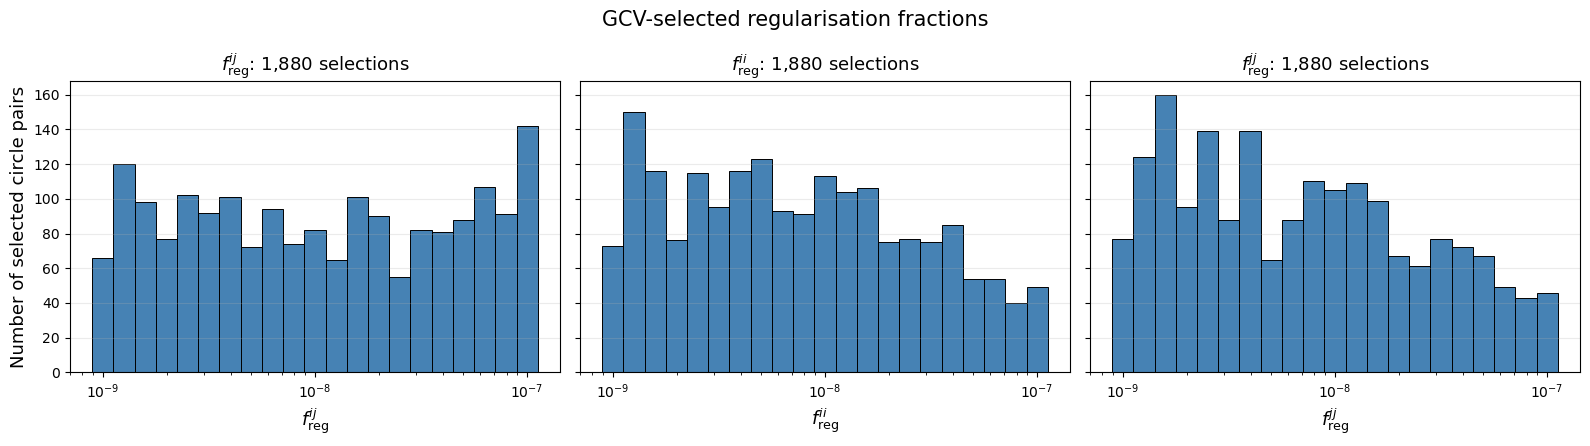

,Quantity,Total,Lower boundary,Lower fraction,Upper boundary,Upper fraction,Any boundary,Boundary fraction
0,ij,1880,66,3.51%,142,7.55%,208,11.06%
1,ii,1880,73,3.88%,49,2.61%,122,6.49%
2,jj,1880,77,4.10%,46,2.45%,123,6.54%


In [12]:
from pathlib import Path

import numpy as np
import pandas as pd


# ==================================================
# Load f_reg selections from blind MASTER-like search
# ==================================================

result_dir = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
) / "MASTER_E1_full_sep179p0"

f_reg_files = sorted(
    result_dir.glob(
        "MASTER_E1_r*_sep179p0_mpi_0.dat"
    )
)

if len(f_reg_files) == 0:
    raise RuntimeError(
        "No MASTER f_reg output files found."
    )


f_reg_rows = []

for file in f_reg_files:

    data = np.loadtxt(
        file
    )

    for row in data:
        f_reg_rows.append(
            {
                "alpha_deg": row[0],
                "Smax": row[1],
                "f_reg_ij": row[2],
                "f_reg_ii": row[3],
                "f_reg_jj": row[4],
            }
        )

f_reg_table = pd.DataFrame(
    f_reg_rows
)

print(
    f"Loaded {len(f_reg_files)} files"
)

print(
    f"Loaded {len(f_reg_table):,} "
    "circle-pair selections"
)


# The Fortran search used 21 logarithmically spaced values
# from 10^-9 to 10^-7.
f_reg_grid = np.logspace(
    -9.0,
    -7.0,
    21,
)

# Construct bin edges halfway between the grid points
# in log10 space.
log_grid = np.log10(
    f_reg_grid
)

log_step = (
    log_grid[1]
    - log_grid[0]
)

log_edges = np.concatenate(
    [
        [log_grid[0] - log_step / 2.0],
        (
            log_grid[:-1]
            + log_grid[1:]
        ) / 2.0,
        [log_grid[-1] + log_step / 2.0],
    ]
)

f_reg_bin_edges = (
    10.0**log_edges
)


# ==================================================
# Plot one histogram for ij, ii and jj
# ==================================================

quantities = [
    ("f_reg_ij", r"$f_{\rm reg}^{ij}$"),
    ("f_reg_ii", r"$f_{\rm reg}^{ii}$"),
    ("f_reg_jj", r"$f_{\rm reg}^{jj}$"),
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4.5),
    sharey=True,
)

for axis, (
    column,
    label,
) in zip(
    axes,
    quantities,
):

    values = (
        f_reg_table[column]
        .dropna()
        .to_numpy()
    )

    axis.hist(
        values,
        bins=f_reg_bin_edges,
        color="steelblue",
        edgecolor="black",
        linewidth=0.7,
    )

    axis.set_xscale("log")

    axis.set_xlabel(
        label,
        fontsize=13,
    )

    axis.set_title(
        f"{label}: {len(values):,} selections",
        fontsize=13,
    )

    axis.grid(
        alpha=0.25,
        axis="y",
    )

axes[0].set_ylabel(
    "Number of selected circle pairs",
    fontsize=13,
)

fig.suptitle(
    "GCV-selected regularisation fractions",
    fontsize=15,
)

fig.tight_layout()

plt.show()

F_REG_MIN = 1.0e-9
F_REG_MAX = 1.0e-7

boundary_rows = []

for quantity in ["ij", "ii", "jj"]:

    values = f_reg_table[
        f"f_reg_{quantity}"
    ].to_numpy()

    lower_count = np.count_nonzero(
        np.isclose(
            values,
            F_REG_MIN,
            rtol=1.0e-10,
            atol=0.0,
        )
    )

    upper_count = np.count_nonzero(
        np.isclose(
            values,
            F_REG_MAX,
            rtol=1.0e-10,
            atol=0.0,
        )
    )

    total = len(values)

    boundary_rows.append(
        {
            "Quantity": quantity,
            "Total": total,
            "Lower boundary": lower_count,
            "Lower fraction": lower_count / total,
            "Upper boundary": upper_count,
            "Upper fraction": upper_count / total,
            "Any boundary": lower_count + upper_count,
            "Boundary fraction": (
                lower_count + upper_count
            ) / total,
        }
    )

boundary_table = pd.DataFrame(
    boundary_rows
)

display(
    boundary_table.style.format(
        {
            "Lower fraction": "{:.2%}",
            "Upper fraction": "{:.2%}",
            "Boundary fraction": "{:.2%}",
        }
    )
)